
# Exploratory Data Analysis of the S&P SL20 Constituent Stocks (2002–2025)
### Colombo Stock Exchange (CSE) — Daily Trading Data for the 20 S&P SL20 Index Companies

**Prepared for:** Multi-Agent Stock Analysis and Recommendation System — Research Project
**Dataset:** `SP20_CSE_Dataset_2001_2025_Adjusted.xlsx`
**Scope of this notebook:** Exploratory Data Analysis (EDA) only.

> **Consolidation note:** two earlier draft EDA notebooks were produced for this dataset during development. This notebook supersedes both — it keeps the self-contained, dependency-free structure of the more complete draft (no external utility modules or pre-joined index/market-stat files required beyond the single `SP20_CSE_Dataset_2001_2025_Adjusted.xlsx` file), and adds an explicit **outlier handling** step (Section 10.2) that neither earlier draft actually performed — both previously only *flagged* outliers without treating them.

> **Note on scope:** This notebook is strictly limited to exploration, data quality assessment,
> descriptive statistics, and statistical inference on relationships already present in the data.
> It deliberately excludes forecasting, machine learning, predictive modelling, decision-support
> algorithms, and model evaluation — those belong to later stages of the project pipeline.



## 1. Introduction

### 1.1 Research Background
The Colombo Stock Exchange (CSE) is Sri Lanka's principal securities market. The **S&P SL20**
is a free-float, market-capitalisation-weighted index composed of the 20 most liquid and
representative companies listed on the CSE, spanning banking, finance, diversified holdings,
telecommunications, energy, and consumer sectors. Because these 20 counters are the most
actively traded on the exchange, they form a natural, data-rich subset on which to build and
validate a multi-agent stock analysis system (fundamental, technical, sentiment, and ML-based
prediction agents feeding a composite ranking and alerting layer).

Before any predictive or recommendation logic can be trusted, the underlying data must be
understood: its structure, its quality, its distributions, and the relationships between its
variables. That is the sole purpose of this notebook.

### 1.2 Research Objectives
This EDA aims to:

1. Establish the structural integrity of the dataset (dimensions, types, keys, duplicates, missingness).
2. Quantify data quality issues that any downstream model must account for.
3. Classify every variable by type and measurement scale.
4. Engineer a small set of transparent, non-predictive descriptive features (e.g. typical price,
   log returns, liquidity tiers, sector grouping) that make later analysis more meaningful.
5. Characterise the distribution, spread, and outlier behaviour of every numerical variable.
6. Test formally whether key variables are normally distributed.
7. Compare trading behaviour across companies, sectors, quarters, and days of the week.
8. Explore trends over the 2002–2025 period without forecasting.
9. Quantify relationships and correlations between price, volume, turnover, and volatility variables.
10. Run appropriate statistical hypothesis tests (Shapiro-Wilk, Kruskal-Wallis/ANOVA, Chi-Square).
11. Translate the findings into concrete "Stock Insights" and a decision-support discussion that
    frames — but does not build — the next stage of the project.

### 1.3 Dataset Overview
The dataset contains **daily trading records for the 20 S&P SL20 constituent companies**
from **2002 to 2025**, merged from multiple CSE source files using a composite key of
`CompanyCode + Date`. Market-wide index values were joined on `Date` alone; company-level
quarterly Beta and annual Market Capitalisation were joined on `CompanyCode` (+ `Year`/`Quarter`)
in the original consolidated dataset — this S&P SL20 subset carries forward the daily OHLCV
fields plus several pre-computed technical fields (`MA_30d`, `MA_90d`, `Volatility_30d_Ann`,
`DailyReturn_Pct`, `PriceRange`, `TurnoverPerShare`).

### 1.4 Importance of EDA
EDA is the safeguard against building a plausible-looking but untrustworthy model. In financial
time-series specifically, EDA is what surfaces survivorship gaps (companies listed mid-period),
non-ordinary share classes mixed in with ordinary shares, price fields that don't reconcile with
each other, and the fact that daily returns are almost never normally distributed — all of which
directly shape how the Feature Engineering, Prediction, and Ranking agents should be designed
later. Skipping this step is the single most common cause of silently broken financial ML systems.



## 2. Data Loading

We import the libraries used throughout the notebook and load the dataset directly from the
Excel source file. The file is expected to sit in the same directory as this notebook.


In [1]:

# --- Core libraries ---
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# --- Statistics ---
from scipy import stats
import statsmodels.api as sm

# --- Global display / plotting settings (publication-quality defaults) ---
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (10, 5),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 10.5,
    "legend.frameon": False,
})

PALETTE = sns.color_palette("crest", 20)
RANDOM_STATE = 42

print("Libraries loaded successfully.")


Libraries loaded successfully.


In [2]:

DATA_PATH = "SP20_CSE_Dataset_2001_2025_Adjusted.xlsx"

df_raw = pd.read_excel(DATA_PATH)

print(f"Dataset loaded: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()


Dataset loaded: 86,950 rows x 24 columns


,Date,CompanyCode,ShortName,MainType,SubType,Open,High,Low,Close,TradeVolume,ShareVolume,Turnover,Era,CompanyName_Official,Year,Month,Quarter,DayOfWeek,DailyReturn_Pct,PriceRange,MA_30d,MA_90d,Volatility_30d_Ann,TurnoverPerShare
0,2012-03-27,AEL,ACCESS ENG SL,N,0.0000,NaN,29.3000,25.0000,26.3000,801,"1,222,719.0000","33,202,756.2000",2001-2025,Access Engineering PLC,2012,3,1,Tuesday,NaN,4.3000,26.3000,26.3000,NaN,27.1549
1,2012-03-28,AEL,ACCESS ENG SL,N,0.0000,NaN,27.2000,26.0000,26.2000,75,"79,350.0000","2,076,675.0000",2001-2025,Access Engineering PLC,2012,3,1,Wednesday,-0.3802,1.2000,26.2500,26.2500,NaN,26.1711
2,2012-03-29,AEL,ACCESS ENG SL,N,0.0000,NaN,26.9000,26.1000,26.5000,46,"92,085.0000","2,438,031.0000",2001-2025,Access Engineering PLC,2012,3,1,Thursday,1.1450,0.8000,26.3333,26.3333,NaN,26.4759
3,2012-03-30,AEL,ACCESS ENG SL,N,0.0000,NaN,27.1000,26.0000,26.7000,53,"274,118.0000","7,386,056.5000",2001-2025,Access Engineering PLC,2012,3,1,Friday,0.7547,1.1000,26.4250,26.4250,NaN,26.9448
4,2012-04-02,AEL,ACCESS ENG SL,N,0.0000,NaN,26.6000,25.5000,25.9000,18,"7,596.0000","198,132.8000",2001-2025,Access Engineering PLC,2012,4,2,Monday,-2.9963,1.1000,26.3200,26.3200,NaN,26.0838



## 3. Dataset Inspection

We inspect the dataset's basic structure: dimensions, column names and types, missing values,
duplicate records, cardinality of each column, and memory footprint.


In [3]:

print("DIMENSIONS")
print("-" * 60)
print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]}")
print(f"Date span: {df_raw['Date'].min().date()}  to  {df_raw['Date'].max().date()}")
print(f"Companies: {df_raw['CompanyCode'].nunique()} unique CompanyCode values")


DIMENSIONS
------------------------------------------------------------
Rows    : 86,950
Columns : 24
Date span: 2002-01-02  to  2025-12-31
Companies: 20 unique CompanyCode values


In [4]:

inspection = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_missing": df_raw.isnull().sum(),
    "pct_missing": (df_raw.isnull().mean() * 100).round(2),
    "n_unique": df_raw.nunique(),
})
inspection.index.name = "Variable"
inspection


,dtype,n_missing,pct_missing,n_unique
Variable,,,,
Date,datetime64[us],0,0.0000,5121
CompanyCode,str,0,0.0000,20
ShortName,str,20093,23.1100,31
MainType,str,0,0.0000,7
SubType,float64,20318,23.3700,13
Open,float64,52661,60.5600,3965
High,float64,13,0.0100,7423
Low,float64,47,0.0500,7400
Close,float64,0,0.0000,9741


In [5]:

print("DUPLICATE RECORDS")
print("-" * 60)
print(f"Fully duplicated rows                 : {df_raw.duplicated().sum():,}")
print(f"Duplicated on (CompanyCode, Date) key  : {df_raw.duplicated(subset=['CompanyCode','Date']).sum():,}")

print("\nMEMORY USAGE")
print("-" * 60)
mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Total in-memory size: {mem_mb:.2f} MB")


DUPLICATE RECORDS
------------------------------------------------------------
Fully duplicated rows                 : 0
Duplicated on (CompanyCode, Date) key  : 0

MEMORY USAGE
------------------------------------------------------------
Total in-memory size: 19.98 MB



**Brief data quality summary:** the dataset is well-formed at the structural level — there are
**zero fully duplicated rows** and **zero duplicated `(CompanyCode, Date)` composite keys**,
confirming that `CompanyCode + Date` is a valid primary key for this file. However, several
columns (`Open`, `Turnover`, `ShortName`, `SubType`) carry meaningful missingness, and
`CompanyName_Official` / `ShortName` contain multiple inconsistent spellings of the same company
(inspected in Section 4). Companies also have unequal row counts — some (e.g. `MELS`, `AEL`, `PLC`)
were listed on the exchange later than others, which is expected and not a data error, but it does
mean the panel is **unbalanced** and later time-series comparisons must account for differing
history lengths.



## 4. Data Quality Assessment

This section goes beyond the basic inspection above to formally check: missing values by
column and by company, duplicate records under alternate keys, invalid/implausible values, and
range validity of the OHLC price fields. We close with a simple **Data Quality Scorecard**.



### 4.1 Missing Value Analysis


In [6]:

missing_cols = ["Open", "High", "Low", "ShareVolume", "Turnover",
                 "DailyReturn_Pct", "PriceRange", "Volatility_30d_Ann", "TurnoverPerShare"]

missing_by_company = (
    df_raw.groupby("CompanyCode")[missing_cols]
    .apply(lambda g: g.isnull().mean() * 100)
    .round(2)
)
missing_by_company


,Open,High,Low,ShareVolume,Turnover,DailyReturn_Pct,PriceRange,Volatility_30d_Ann,TurnoverPerShare
CompanyCode,,,,,,,,,
AEL,33.9600,0.0000,0.0000,0.0000,8.9900,0.0400,0.0000,0.1900,8.9900
CFIN,64.0000,0.0000,0.0200,0.0000,4.7900,0.0200,0.0200,0.1000,4.7900
COMB,65.4800,0.0000,0.0800,0.0000,4.7000,0.0200,0.0800,0.1000,4.7000
DFCC,64.7100,0.0000,0.0400,0.0000,4.8100,0.0200,0.0400,0.1000,4.8100
DIAL,58.6800,0.0000,0.0000,0.0000,5.6000,0.0200,0.0000,0.1200,5.6000
HAYL,64.0700,0.0000,0.0000,0.0000,4.9400,0.0200,0.0000,0.1000,4.9400
HHL,61.7100,0.0000,0.0000,0.0000,5.1700,0.0200,0.0000,0.1100,5.1700
HNB,65.4700,0.0400,0.0400,0.0000,4.7000,0.0200,0.0400,0.1000,4.7000
JKH,65.7300,0.0000,0.2200,0.1800,4.8200,0.0200,0.2200,0.1000,4.8200


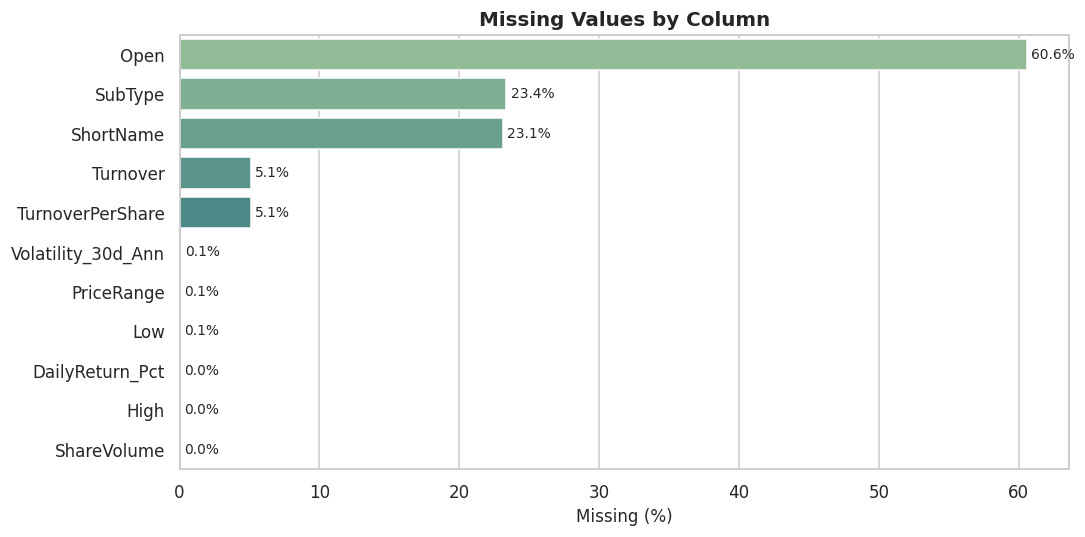

In [7]:

fig, ax = plt.subplots(figsize=(10, 5))
missing_pct = (df_raw.isnull().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

sns.barplot(x=missing_pct.values, y=missing_pct.index, palette="crest", ax=ax)
ax.set_xlabel("Missing (%)")
ax.set_ylabel("")
ax.set_title("Missing Values by Column")
for i, v in enumerate(missing_pct.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.show()



**Interpretation:** `Open` is missing in roughly 60% of rows and `Turnover` in about 5% — this is
consistent with how CSE data is reported for illiquid trading days (a trade can print a `Close`
without a distinct `Open` quote being recorded). `ShortName` missingness aligns with `SubType`
missingness, both artefacts of how ticker metadata was captured historically. Because missingness
is **not random** (it is concentrated in specific fields and specific eras), we do **not** apply a
blanket imputation — for OHLC fields, silently filling `Open` would fabricate price information
for a Buy/Hold/Sell system. We treat missingness itself as informative and carry it forward as-is
into the numerical analysis (using `dropna` scoped to the exact columns each statistic needs,
rather than dropping whole rows).



### 4.2 Duplicate Analysis


In [8]:

print("Exact duplicate rows                          :", df_raw.duplicated().sum())
print("Duplicates on (CompanyCode, Date)              :", df_raw.duplicated(subset=["CompanyCode", "Date"]).sum())
print("Duplicates on (CompanyCode, Date, MainType)     :", df_raw.duplicated(subset=["CompanyCode", "Date", "MainType"]).sum())
print("Duplicates on (Year, Quarter, CompanyCode)      :", df_raw.duplicated(subset=["Year", "Quarter", "CompanyCode"]).sum(), "(expected: many, since this key is coarser than daily)")


Exact duplicate rows                          : 0
Duplicates on (CompanyCode, Date)              : 0
Duplicates on (CompanyCode, Date, MainType)     : 0
Duplicates on (Year, Quarter, CompanyCode)      : 85402 (expected: many, since this key is coarser than daily)



No exact or key-level duplicates exist at the daily grain. The apparent "duplicates" on the
coarser `(Year, Quarter, CompanyCode)` key are expected — many trading days share the same
year/quarter for the same company — and are not a data quality fault.



### 4.3 Invalid Value Checks & Range Validation


In [9]:

ohlc = df_raw.dropna(subset=["Open", "High", "Low", "Close"]).copy()

check_high_lt_low   = ohlc[ohlc["High"] < ohlc["Low"]]
check_open_out_band  = ohlc[(ohlc["Open"] > ohlc["High"]) | (ohlc["Open"] < ohlc["Low"])]
check_close_out_band = ohlc[(ohlc["Close"] > ohlc["High"]) | (ohlc["Close"] < ohlc["Low"])]
check_negative = df_raw[(df_raw[["Open", "High", "Low", "Close", "TradeVolume",
                                   "ShareVolume", "Turnover"]] < 0).any(axis=1)]

print(f"Rows with High < Low                         : {len(check_high_lt_low):,}")
print(f"Rows with Close outside [Low, High]          : {len(check_close_out_band):,}")
print(f"Rows with Open outside [Low, High]           : {len(check_open_out_band):,}  "
      f"({len(check_open_out_band)/len(ohlc)*100:.1f}% of rows where Open is present)")
print(f"Rows with any negative price/volume value    : {len(check_negative):,}")


Rows with High < Low                         : 0
Rows with Close outside [Low, High]          : 510
Rows with Open outside [Low, High]           : 4,622  (13.5% of rows where Open is present)
Rows with any negative price/volume value    : 0


In [10]:

check_open_out_band[["Date", "CompanyCode", "Open", "High", "Low", "Close"]].head(8)


,Date,CompanyCode,Open,High,Low,Close
907,2016-01-04,AEL,153.0000,23.8000,23.3000,23.6000
908,2016-01-05,AEL,74.0000,23.8000,23.5000,23.5000
909,2016-01-06,AEL,101.0000,23.6000,23.2000,23.3000
910,2016-01-07,AEL,107.0000,23.2000,22.8000,22.9000
911,2016-01-08,AEL,201.0000,23.1000,22.4000,22.6000
912,2016-01-11,AEL,168.0000,22.9000,21.8000,22.1000
913,2016-01-12,AEL,155.0000,22.3000,21.5000,21.5000
914,2016-01-13,AEL,161.0000,22.5000,21.5000,22.2000



**Key finding:** `High < Low` never occurs and no negative prices/volumes exist — the core
OHLC relationship (`Low ≤ Close ≤ High`) is intact. However, **`Open` falls outside the
`[Low, High]` band in a non-trivial share of the rows where it is present** — sometimes by an
order of magnitude (e.g. `Open = 153` on a day where `High/Low/Close` all sit near `23`). This
is a genuine data quality issue in the `Open` field specifically, most plausibly caused by a
scale/unit inconsistency or misalignment during the original CSE extract, not by the `High`,
`Low`, or `Close` fields. **Recommendation for downstream work:** treat `Open` as unreliable;
prefer `High`, `Low`, `Close`, and derived measures (e.g. the `TypicalPrice` engineered in
Section 6) over `Open`-based features such as intraday gap.


In [11]:

# Data Quality Scorecard
n_rows = len(df_raw)
scorecard = pd.DataFrame({
    "Check": [
        "No fully duplicated rows",
        "Composite key (CompanyCode+Date) unique",
        "No High < Low violations",
        "No negative prices/volumes",
        "Close within [Low, High]",
        "Open within [Low, High] (where present)",
        "Core price field (Close) complete",
    ],
    "Result": [
        "PASS" if df_raw.duplicated().sum() == 0 else "FAIL",
        "PASS" if df_raw.duplicated(subset=["CompanyCode", "Date"]).sum() == 0 else "FAIL",
        "PASS" if len(check_high_lt_low) == 0 else "FAIL",
        "PASS" if len(check_negative) == 0 else "FAIL",
        "PASS" if len(check_close_out_band) == 0 else "FAIL",
        f"WARN ({len(check_open_out_band)/len(ohlc)*100:.1f}% violate)",
        "PASS" if df_raw['Close'].isnull().sum() == 0 else "FAIL",
    ],
})
scorecard


,Check,Result
0,No fully duplicated rows,PASS
1,Composite key (CompanyCode+Date) unique,PASS
2,No High < Low violations,PASS
3,No negative prices/volumes,PASS
4,"Close within [Low, High]",FAIL
5,"Open within [Low, High] (where present)",WARN (13.5% violate)
6,Core price field (Close) complete,PASS



## 5. Variable Classification

Each variable is classified by its **statistical type** (numerical, categorical, temporal) and
its **measurement scale** (nominal, ordinal, interval, ratio). This drives which descriptive
statistics and tests are valid for it later in the notebook.


In [12]:

def classify_variable(col, s):
    if pd.api.types.is_datetime64_any_dtype(s):
        return "Temporal", "Interval"
    if col in ["Year", "Month", "Quarter"]:
        return "Temporal", "Ordinal"
    if pd.api.types.is_numeric_dtype(s):
        return "Numerical", "Ratio"
    return "Categorical", "Nominal"

classification = pd.DataFrame(
    [(c, *classify_variable(c, df_raw[c])) for c in df_raw.columns],
    columns=["Variable", "Statistical Type", "Measurement Scale"],
).set_index("Variable")
classification


,Statistical Type,Measurement Scale
Variable,,
Date,Temporal,Interval
CompanyCode,Categorical,Nominal
ShortName,Categorical,Nominal
MainType,Categorical,Nominal
SubType,Numerical,Ratio
Open,Numerical,Ratio
High,Numerical,Ratio
Low,Numerical,Ratio
Close,Numerical,Ratio



A few judgement calls worth stating explicitly:

| Variable | Type | Scale | Reasoning |
|---|---|---|---|
| `Date` | Temporal | Interval | Differences are meaningful, no true zero |
| `Year`, `Quarter`, `Month` | Temporal (derived) | Ordinal | Ordered, but treated as ordinal groupers rather than raw numbers in comparisons |
| `DayOfWeek` | Categorical | Ordinal (weak) | Has a natural Mon→Fri order but no meaningful "distance" between days |
| `CompanyCode`, `ShortName`, `CompanyName_Official`, `Era` | Categorical | Nominal | Labels only |
| `MainType` | Categorical | Nominal | Instrument class (N = ordinary shares, X/W/R/D/P/B = non-ordinary) |
| `Open, High, Low, Close, Turnover, TradeVolume, ShareVolume` | Numerical | Ratio | True zero exists (e.g. zero volume), ratios are meaningful |
| `DailyReturn_Pct` | Numerical | Interval/Ratio (hybrid) | Percent change — zero is meaningful (no change) but negative values exist, so ratios of returns aren't always interpretable the way ratios of prices are |



## 6. Feature Engineering

We engineer a small number of **transparent, descriptive** features that make the rest of the
EDA more informative. None of these are predictive/lagged-target features — they only describe
the data as it already is.

1. **`MainType == 'N'` filter → `df`**: restricts the working dataset to ordinary shares only,
   excluding warrants, rights issues, and other non-ordinary instrument classes (`X, W, R, D, P, B`)
   that trade under fundamentally different price dynamics and would distort company-level
   comparisons if mixed in.
2. **`Sector`**: each of the 20 companies is mapped to its publicly known sector (Banking,
   Diversified Holdings, Finance/NBFI, Telecommunications, Energy, Consumer). This turns
   20 individual tickers into 6 interpretable groups for comparison and correlation analysis.
3. **`TypicalPrice`**: `(High + Low + Close) / 3`, a standard technical-analysis price proxy that
   avoids the unreliable `Open` field identified in Section 4.
4. **`LogReturn`**: `ln(Close_t / Close_{t-1})`, computed per company. Log returns are the standard
   choice in finance because they are additive over time and better approximate normality than
   simple percentage returns — useful for the normality and correlation sections below.
5. **`LiquidityTier`**: quartile bucket (`Low/Medium/High/Very High`) of `TurnoverPerShare`,
   giving a simple categorical liquidity grouping for group comparisons.
6. **`VolatilityRegime`**: quartile bucket of `Volatility_30d_Ann` (`Low/Medium/High/Very High`),
   used later for group comparison and as a categorical variable in Chi-Square testing.
7. **`MonthName`**: ordered categorical version of `Month`, purely for readable seasonal charts.


In [13]:

# 6.1 Filter to ordinary shares only
df = df_raw[df_raw["MainType"] == "N"].copy()
print(f"Rows after filtering to ordinary shares (MainType == 'N'): {len(df):,} "
      f"({len(df)/len(df_raw)*100:.1f}% of raw rows)")

# 6.2 Sector mapping (publicly known CSE / S&P SL20 sector classification)
sector_map = {
    "COMB": "Banking", "HNB": "Banking", "DFCC": "Banking", "NDB": "Banking",
    "NTB": "Banking", "SAMP": "Banking", "SEYB": "Banking",
    "CFIN": "Finance / NBFI", "LFIN": "Finance / NBFI", "LOLC": "Finance / NBFI", "PLC": "Finance / NBFI",
    "AEL": "Diversified Holdings", "HAYL": "Diversified Holdings", "HHL": "Diversified Holdings",
    "JKH": "Diversified Holdings", "MELS": "Diversified Holdings", "SUN": "Diversified Holdings",
    "DIAL": "Telecommunications",
    "LIOC": "Energy",
    "SINS": "Consumer / Retail",
}
df["Sector"] = df["CompanyCode"].map(sector_map)

# 6.3 Typical price (avoids the unreliable Open field)
df["TypicalPrice"] = (df["High"] + df["Low"] + df["Close"]) / 3

# 6.4 Log return, computed per company on sorted dates
df = df.sort_values(["CompanyCode", "Date"])
df["LogReturn"] = df.groupby("CompanyCode")["Close"].transform(lambda s: np.log(s / s.shift(1)))

# 6.5 Liquidity tier (quartiles of TurnoverPerShare)
df["LiquidityTier"] = pd.qcut(df["TurnoverPerShare"], 4,
                                labels=["Low", "Medium", "High", "Very High"])

# 6.6 Volatility regime (quartiles of Volatility_30d_Ann)
df["VolatilityRegime"] = pd.qcut(df["Volatility_30d_Ann"], 4,
                                   labels=["Low", "Medium", "High", "Very High"])

# 6.7 Ordered month name for readable seasonal charts
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
df["MonthName"] = pd.Categorical(df["Month"].apply(lambda m: month_names[m-1]),
                                   categories=month_names, ordered=True)

print("\nEngineered columns added: Sector, TypicalPrice, LogReturn, LiquidityTier, VolatilityRegime, MonthName")
df[["Date","CompanyCode","Sector","Close","TypicalPrice","LogReturn","LiquidityTier","VolatilityRegime"]].head()


Rows after filtering to ordinary shares (MainType == 'N'): 79,088 (91.0% of raw rows)



Engineered columns added: Sector, TypicalPrice, LogReturn, LiquidityTier, VolatilityRegime, MonthName


,Date,CompanyCode,Sector,Close,TypicalPrice,LogReturn,LiquidityTier,VolatilityRegime
0,2012-03-27,AEL,Diversified Holdings,26.3000,26.8667,NaN,Medium,NaN
1,2012-03-28,AEL,Diversified Holdings,26.2000,26.4667,-0.0038,Medium,NaN
2,2012-03-29,AEL,Diversified Holdings,26.5000,26.5000,0.0114,Medium,NaN
3,2012-03-30,AEL,Diversified Holdings,26.7000,26.6000,0.0075,Medium,NaN
4,2012-04-02,AEL,Diversified Holdings,25.9000,26.0000,-0.0304,Medium,NaN



## 7. Categorical Variable Analysis

For each key categorical variable we produce a frequency table, a percentage table, and a bar
chart. A pie chart is used only where the variable has a small number of roughly-comparable-sized
categories (`Sector`), since pie charts become unreadable with many categories (`CompanyCode`)
or heavily skewed shares (`MainType`).


In [14]:

def freq_table(series, name):
    tbl = series.value_counts(dropna=False).to_frame("Count")
    tbl["Percentage (%)"] = (tbl["Count"] / tbl["Count"].sum() * 100).round(2)
    tbl.index.name = name
    return tbl

cat_vars = ["CompanyCode", "Sector", "MainType", "DayOfWeek", "LiquidityTier", "VolatilityRegime"]
for c in cat_vars:
    print(f"\n=== {c} ===")
    display(freq_table(df[c], c))



=== CompanyCode ===


,Count,Percentage (%)
CompanyCode,,
NDB,5025,6.3500
DFCC,4976,6.2900
SAMP,4963,6.2800
JKH,4958,6.2700
NTB,4827,6.1000
HAYL,4819,6.0900
CFIN,4782,6.0500
LOLC,4697,5.9400
HHL,4481,5.6700



=== Sector ===


,Count,Percentage (%)
Sector,,
Banking,28025,35.4400
Diversified Holdings,21467,27.1400
Finance / NBFI,16464,20.8200
Consumer / Retail,4466,5.6500
Energy,4399,5.5600
Telecommunications,4267,5.4000



=== MainType ===


...

,Count,Percentage (%)
DayOfWeek,,
Tuesday,16054,20.3000
Wednesday,15989,20.2200
Thursday,15939,20.1500
Monday,15577,19.7000
Friday,15529,19.6400



=== LiquidityTier ===


,Count,Percentage (%)
LiquidityTier,,
High,18756,23.7200
Low,18739,23.6900
Medium,18738,23.6900
Very High,18721,23.6700
NaN,4134,5.2300



=== VolatilityRegime ===


,Count,Percentage (%)
VolatilityRegime,,
Low,19749,24.9700
Very High,19748,24.9700
Medium,19747,24.9700
High,19747,24.9700
NaN,97,0.1200


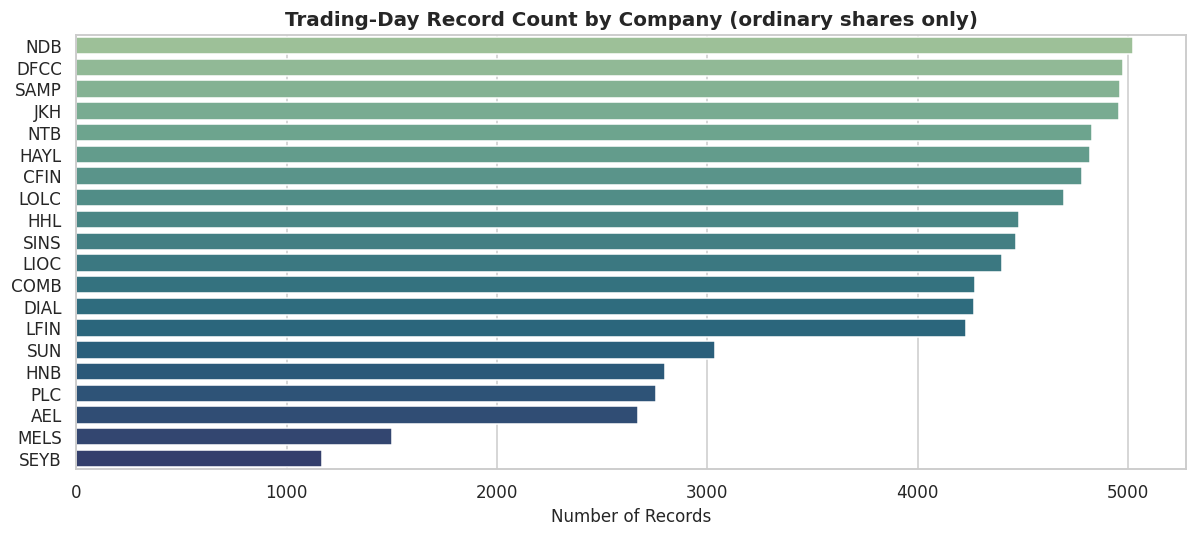

In [15]:

fig, ax = plt.subplots(figsize=(11, 5))
order = df["CompanyCode"].value_counts().index
sns.countplot(data=df, y="CompanyCode", order=order, palette="crest", ax=ax)
ax.set_title("Trading-Day Record Count by Company (ordinary shares only)")
ax.set_xlabel("Number of Records")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


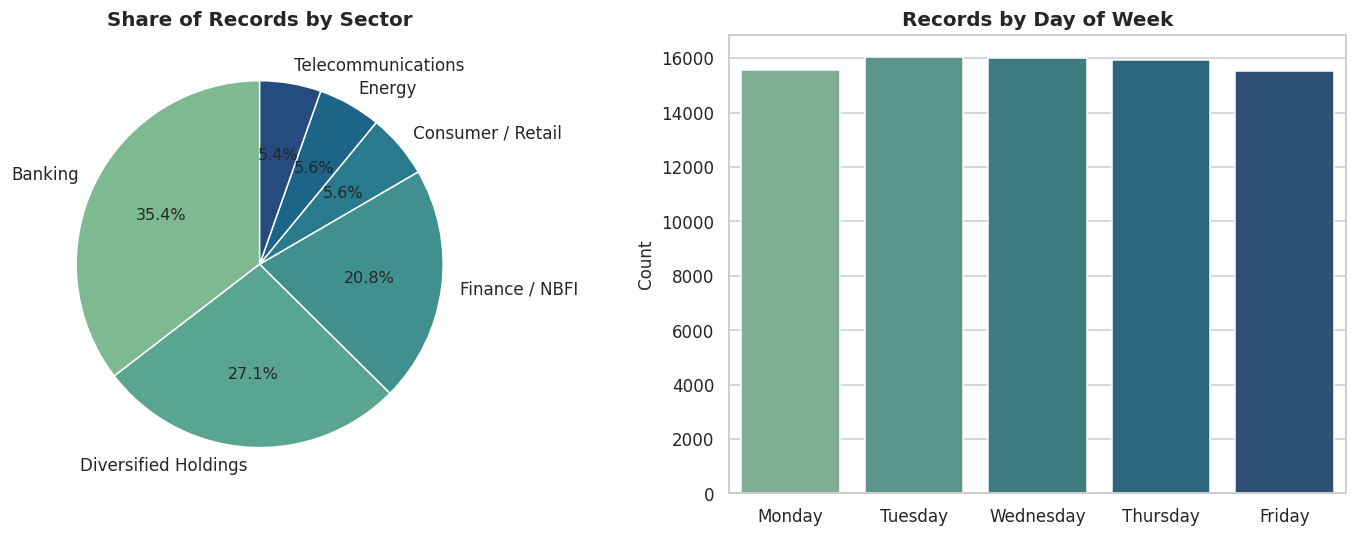

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sector_counts = df["Sector"].value_counts()
axes[0].pie(sector_counts.values, labels=sector_counts.index, autopct="%1.1f%%",
            colors=sns.color_palette("crest", len(sector_counts)), startangle=90)
axes[0].set_title("Share of Records by Sector")

sns.countplot(data=df, x="DayOfWeek", order=["Monday","Tuesday","Wednesday","Thursday","Friday"],
              palette="crest", ax=axes[1])
axes[1].set_title("Records by Day of Week")
axes[1].set_xlabel("")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()



**Interpretation:** Banking dominates the sector mix (7 of 20 constituents), reflecting the
CSE's historical concentration in financial-sector listings. Record counts are near-uniform
across weekdays (as expected — the exchange trades Mon–Fri with no structural bias), which is
a useful sanity check that no weekday's data was systematically dropped during extraction.
Company-level record counts differ because listing dates differ (Section 3), not because of
data loss.



## 8. Numerical Variable Analysis

For every numerical variable — including the engineered `TypicalPrice` and `LogReturn` — we
compute mean, median, mode, standard deviation, variance, min, max, quartiles, IQR, coefficient
of variation (CV), skewness, and kurtosis.


In [17]:

num_vars = ["Open", "High", "Low", "Close", "TypicalPrice", "TradeVolume", "ShareVolume",
            "Turnover", "TurnoverPerShare", "DailyReturn_Pct", "LogReturn", "PriceRange",
            "MA_30d", "MA_90d", "Volatility_30d_Ann"]

def describe_full(series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    mean = s.mean()
    std = s.std()
    return pd.Series({
        "count": s.count(),
        "mean": mean,
        "median": s.median(),
        "mode": s.mode().iloc[0] if not s.mode().empty else np.nan,
        "std": std,
        "variance": s.var(),
        "min": s.min(),
        "Q1": q1,
        "Q3": q3,
        "max": s.max(),
        "IQR": q3 - q1,
        "CV (%)": (std / mean * 100) if mean != 0 else np.nan,
        "skewness": s.skew(),
        "kurtosis": s.kurt(),
    })

summary_stats = pd.DataFrame({v: describe_full(df[v]) for v in num_vars}).T
summary_stats


,count,mean,median,mode,std,variance,min,Q1,Q3,max,IQR,CV (%),skewness,kurtosis
Open,"32,233.0000",80.3712,64.0000,90.0000,84.8521,"7,199.8766",0.1000,22.1000,110.0000,"1,767.0000",87.9000,105.5752,3.4539,21.5890
High,"79,078.0000",75.2356,58.0000,90.0000,77.9882,"6,082.1597",0.5625,22.3000,105.0000,"1,600.0000",82.7000,103.6587,4.6856,51.1257
Low,"79,044.0000",73.6878,56.5000,90.0000,76.0756,"5,787.4940",0.5625,21.7500,103.0000,"1,400.0000",81.2500,103.2404,4.5088,47.0585
Close,"79,088.0000",74.4307,57.0000,90.0000,77.1149,"5,946.7044",0.5625,22.0000,104.0000,"1,439.9000",82.0000,103.6062,4.6094,49.0449
TypicalPrice,"79,039.0000",74.4016,57.1444,80.0000,76.8443,"5,905.0540",0.5625,22.0000,104.0000,"1,453.4000",82.0000,103.2832,4.5778,48.8701
TradeVolume,"79,088.0000","17,591.6588",50.0000,6.0000,"413,884.1646","171,300,101,691.7226",1.0000,18.0000,142.0000,"51,451,183.0000",124.0000,"2,352.7296",76.7059,"7,722.2788"
ShareVolume,"79,076.0000","1,824,244.8623","67,200.0000",300.0000,"22,481,887.0641","505,435,245,963,338.1250",1.0000,"12,000.0000","347,831.5000","2,782,450,246.0000","335,831.5000","1,232.3942",54.7020,"4,926.0832"
Turnover,"74,954.0000","31,661,115.4259","2,639,536.6500","20,000.0000","188,331,763.8075","35,468,853,258,830,524.0000",16.1000,"414,328.0250","16,420,754.9500","23,115,744,427.8000","16,006,426.9250",594.8362,56.1707,"5,008.5054"
TurnoverPerShare,"74,954.0000",74.1983,56.3869,90.0000,78.1226,"6,103.1479",0.5625,21.6844,103.0000,"1,447.6424",81.3156,105.2891,4.6757,49.3124
DailyReturn_Pct,"79,069.0000",11.4952,0.0000,0.0000,857.4199,"735,168.9130",-93.8462,-0.7752,0.9258,"137,137.2372",1.7010,"7,458.9316",122.5251,"15,932.8698"



**Reading the table:** `Close`, `TypicalPrice`, and the moving averages all show high positive
skew and CV well above 60–70%, meaning the price scale is dominated by a handful of
high-priced counters (e.g. `JKH`, banking names) while most sit far lower — typical for a
cross-section of stocks priced in local-currency rupees rather than a normalised index. Return
and volume-based variables (`DailyReturn_Pct`, `LogReturn`, `TradeVolume`, `Turnover`) show very
high kurtosis (well above the normal benchmark of 3), the classic **"fat tails"** signature of
financial returns — large daily moves are far more frequent than a normal distribution would
predict. This foreshadows the Normality Analysis in Section 11.



## 9. Distribution Analysis

We visualise the distribution of the core price, volume, and return variables using histograms,
histogram+KDE overlays, and boxplots.


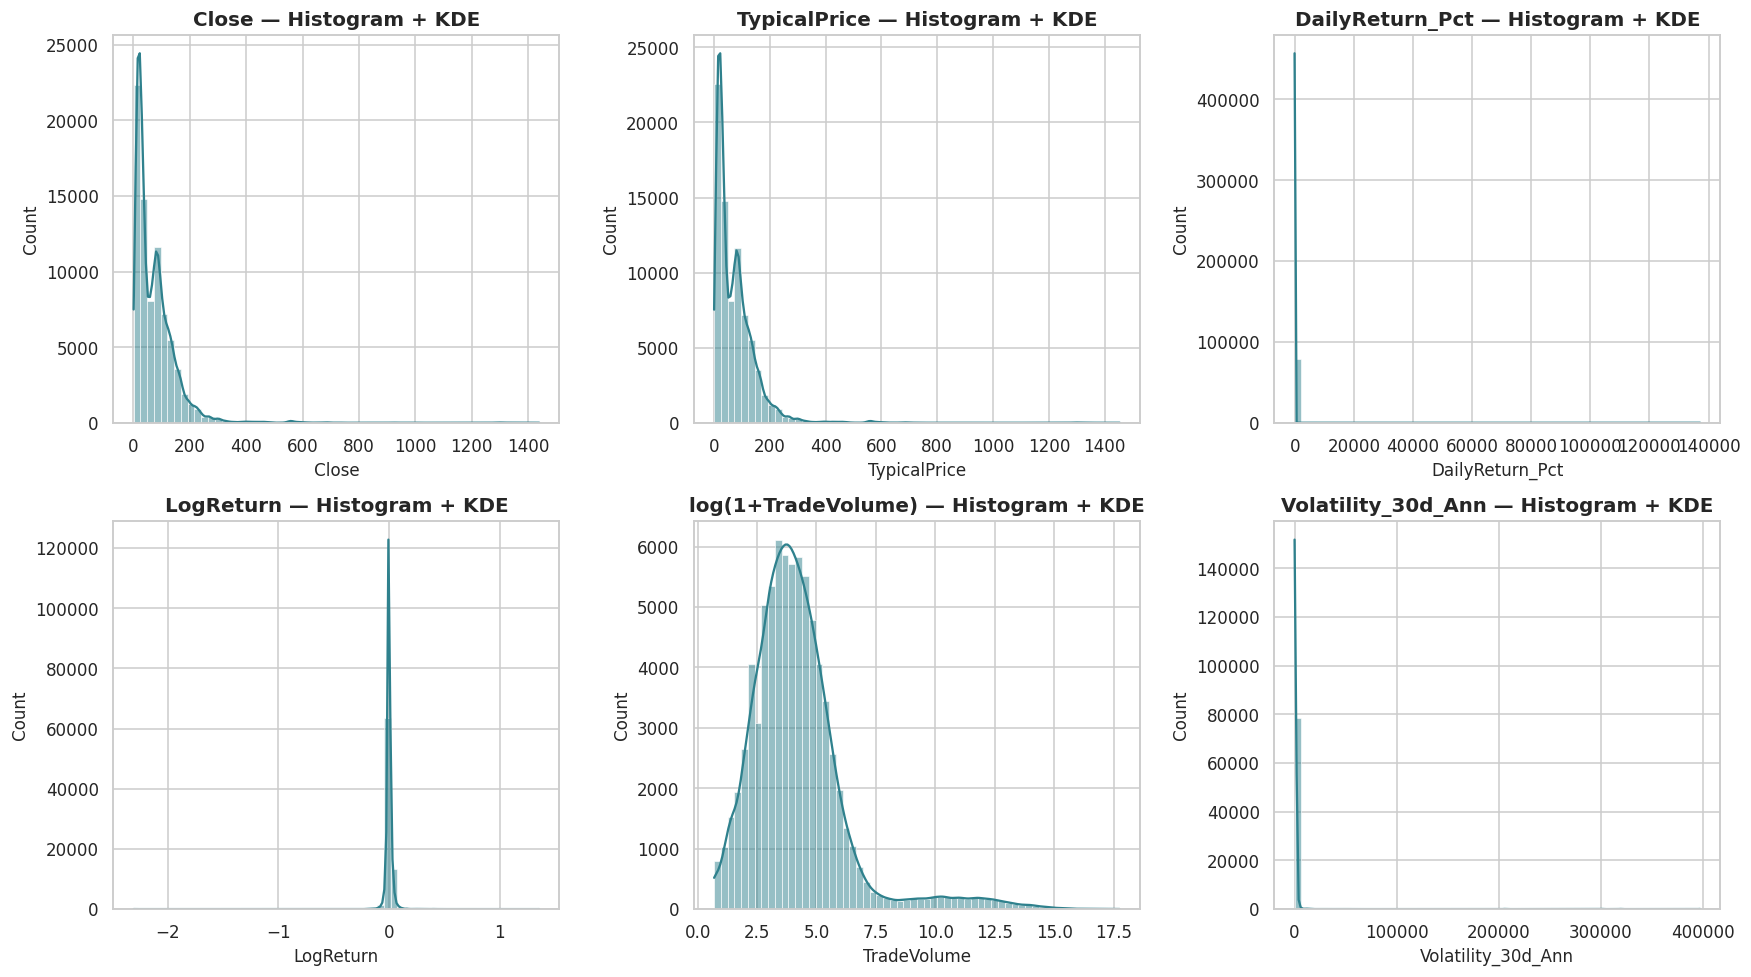

In [18]:

dist_vars = ["Close", "TypicalPrice", "DailyReturn_Pct", "LogReturn",
             "TradeVolume", "Volatility_30d_Ann"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, v in zip(axes, dist_vars):
    data = df[v].dropna()
    if v == "TradeVolume":
        data = data[data > 0]
        sns.histplot(np.log1p(data), bins=60, kde=True, color=PALETTE[10], ax=ax)
        ax.set_title(f"log(1+{v}) — Histogram + KDE")
    else:
        sns.histplot(data, bins=60, kde=True, color=PALETTE[10], ax=ax)
        ax.set_title(f"{v} — Histogram + KDE")
plt.tight_layout()
plt.show()


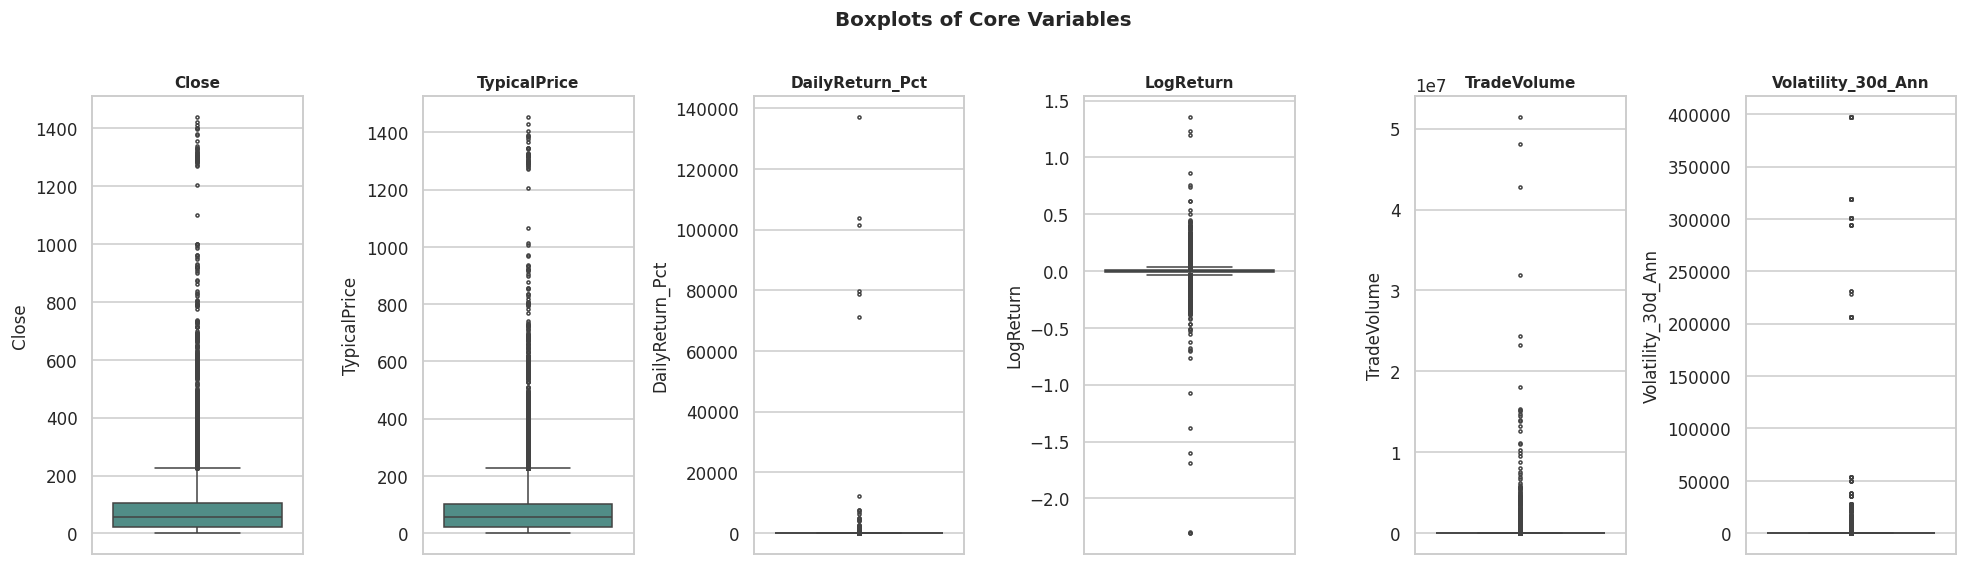

In [19]:

fig, axes = plt.subplots(1, len(dist_vars), figsize=(18, 5))
for ax, v in zip(axes, dist_vars):
    data = df[v].dropna()
    sns.boxplot(y=data, color=PALETTE[7], ax=ax, fliersize=2)
    ax.set_title(v, fontsize=10)
    ax.set_xlabel("")
plt.suptitle("Boxplots of Core Variables", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()



**Distribution / skewness / spread / outliers:**

- **`Close` / `TypicalPrice`** are strongly right-skewed with a long upper tail — most trading
  days sit in the Rs. 20–150 range, with a thin tail of higher-priced counters. This is a
  cross-sectional pricing effect, not an anomaly.
- **`DailyReturn_Pct` / `LogReturn`** are approximately symmetric and tightly clustered around
  zero, but with **very long, thin tails** in the boxplot (dense clouds of "outlier" points
  beyond the whiskers) — hallmark fat-tailed financial return behaviour rather than data error.
- **`TradeVolume` (log-scaled)** is closer to a bell shape once log-transformed, confirming the
  raw scale is heavily right-skewed by a small number of very high-volume days (index
  rebalancing, corporate announcements, block trades).
- **`Volatility_30d_Ann`** is right-skewed, with a cluster of very calm periods and a smaller
  set of unusually turbulent 30-day windows (economic shocks, e.g. 2015, 2019, 2020, 2022).


### 10.2 Outlier Handling

Sections 10 (above) and the boxplots in Section 9 **identified** outliers but did not **treat**
them. We now apply an explicit, transparent treatment so any later stage of the project (feature
engineering, modeling) that is sensitive to extreme values has a documented, reproducible option to
use.

**Method chosen: Winsorization at the 1st / 99th percentile.**

We chose winsorization (capping) rather than deletion, for three reasons specific to this dataset:

1. **No rows are discarded.** Deleting outlier rows in a daily financial time series creates
   artificial gaps in each company's price history, which would silently corrupt every rolling-window
   feature (`MA_30d`, `MA_90d`, `Volatility_30d_Ann`) computed elsewhere in this notebook and in the
   raw file itself.
2. **Percentile-based bounds (1st/99th), not the 1.5×IQR rule used for detection in Section 10.1.**
   The IQR rule flags a large share of `DailyReturn_Pct` observations (a well-known property of
   fat-tailed return distributions — see Section 11) — applying it as a *treatment* would cap far too
   aggressively and remove genuine, information-rich volatility. The 1%/99% percentile bounds are a
   more conservative, standard choice for winsorizing return-like variables in finance.
3. **Applied only to the variables where extreme values are most likely to distort downstream
   statistics**: `DailyReturn_Pct`, `LogReturn`, `TradeVolume`, and `Turnover`.

**Exactly what was done:**

- For each of the four variables above, values below the 1st percentile are **capped up** to the 1st
  percentile value, and values above the 99th percentile are **capped down** to the 99th percentile
  value.
- The winsorization bounds (and the capping itself) are computed **per company**, not across the
  pooled 20-stock dataset — a single global cap would over-treat low-priced/low-volume companies and
  under-treat high-priced/high-volume ones.
- **The original columns are left completely untouched.** Winsorized values are written to new
  columns suffixed `_Winsorized` (e.g. `DailyReturn_Pct_Winsorized`). **Every section of this
  notebook, before and after this point, continues to use the raw, untreated columns by default** —
  the winsorized versions are provided as an explicitly optional, clearly labeled alternative for any
  later stage of the project (feature engineering, modeling) that specifically wants outlier-robust
  inputs; they are not substituted in anywhere else in this EDA.

In [20]:

def winsorize_per_company(frame, col, lower_pct=0.01, upper_pct=0.99):
    '''Cap `col` at its per-company 1st/99th percentile. Returns a new Series aligned to `frame`'s index.'''
    def _cap(s):
        lo, hi = s.quantile(lower_pct), s.quantile(upper_pct)
        return s.clip(lower=lo, upper=hi)
    return frame.groupby("CompanyCode")[col].transform(_cap)

winsorize_cols = ["DailyReturn_Pct", "LogReturn", "TradeVolume", "Turnover"]

for col in winsorize_cols:
    df[f"{col}_Winsorized"] = winsorize_per_company(df, col)

print("Outlier handling applied via per-company 1%/99% winsorization.")
print("New columns added:", [f"{c}_Winsorized" for c in winsorize_cols])
print("\nOriginal columns are unchanged and remain the default for the rest of this notebook.")


Outlier handling applied via per-company 1%/99% winsorization.
New columns added: ['DailyReturn_Pct_Winsorized', 'LogReturn_Winsorized', 'TradeVolume_Winsorized', 'Turnover_Winsorized']

Original columns are unchanged and remain the default for the rest of this notebook.


In [21]:

# Before / after comparison: does winsorization meaningfully change the summary statistics?
comparison_rows = []
for col in winsorize_cols:
    raw = df[col].dropna()
    treated = df[f"{col}_Winsorized"].dropna()
    comparison_rows.append({
        "Variable": col,
        "Mean (raw)": raw.mean(), "Mean (winsorized)": treated.mean(),
        "Std Dev (raw)": raw.std(), "Std Dev (winsorized)": treated.std(),
        "Skewness (raw)": raw.skew(), "Skewness (winsorized)": treated.skew(),
        "Kurtosis (raw)": raw.kurt(), "Kurtosis (winsorized)": treated.kurt(),
        "n_values_capped": int((raw != treated).sum()),
    })

winsor_comparison = pd.DataFrame(comparison_rows).set_index("Variable")
winsor_comparison.round(4)


,Mean (raw),Mean (winsorized),Std Dev (raw),Std Dev (winsorized),Skewness (raw),Skewness (winsorized),Kurtosis (raw),Kurtosis (winsorized),n_values_capped
Variable,,,,,,,,,
DailyReturn_Pct,11.4952,2.6396,857.4199,21.3765,122.5251,12.3559,"15,932.8698",186.5296,1590
LogReturn,0.0004,0.0005,0.0335,0.0208,-14.2779,0.5166,"1,170.4548",6.1560,1588
TradeVolume,"17,591.6588","7,178.1805","413,884.1646","66,666.6156",76.7059,14.1084,"7,722.2788",225.7776,1063
Turnover,"31,661,115.4259","26,859,672.7615","188,331,763.8075","79,230,194.7648",56.1707,7.0064,"5,008.5054",70.3632,1515


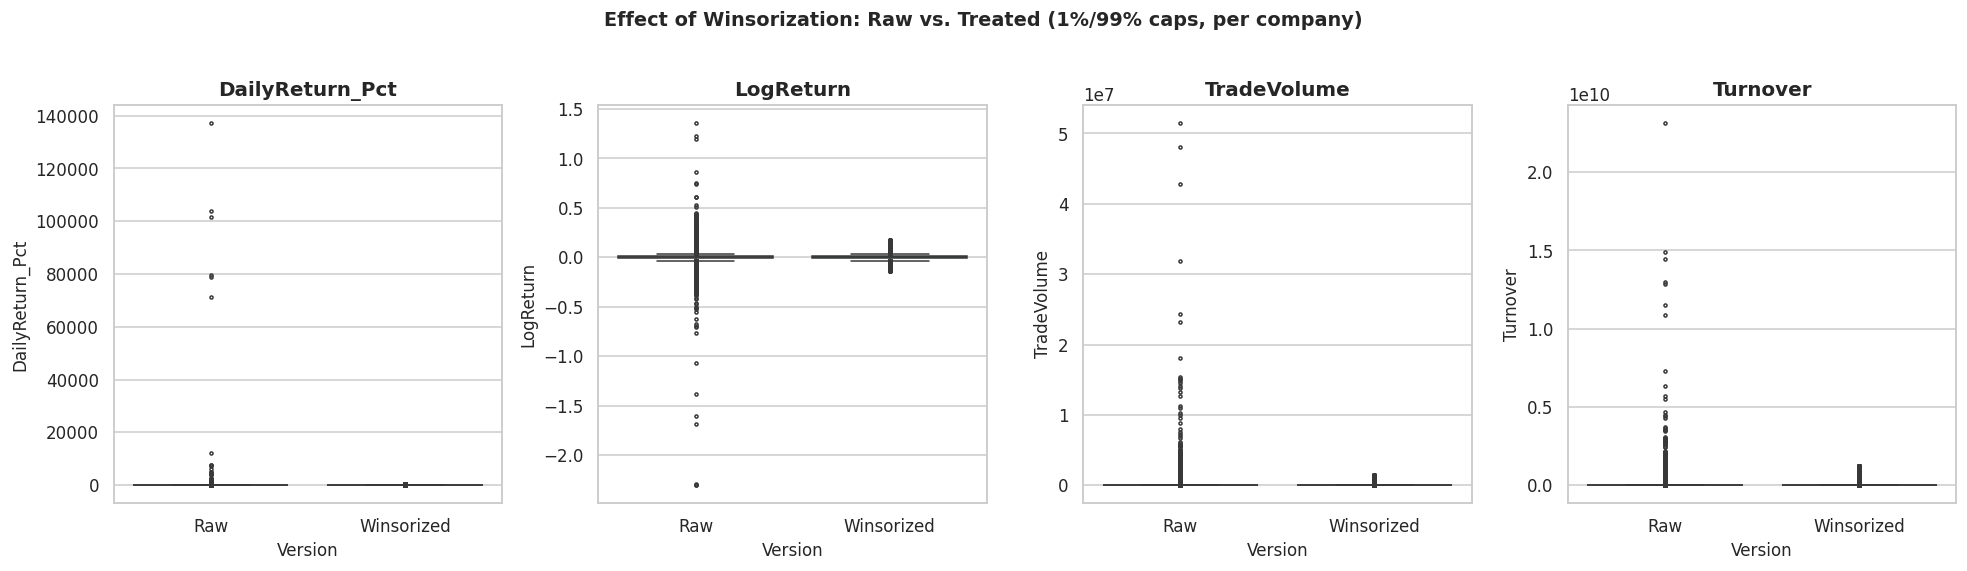

In [22]:

fig, axes = plt.subplots(1, len(winsorize_cols), figsize=(18, 5))
for ax, col in zip(axes, winsorize_cols):
    plot_df = pd.DataFrame({
        "Raw": df[col],
        "Winsorized": df[f"{col}_Winsorized"]
    }).melt(var_name="Version", value_name=col)
    sns.boxplot(data=plot_df, x="Version", y=col, palette=["#9fb8ad", PALETTE[10]], ax=ax, fliersize=2)
    ax.set_title(col)
plt.suptitle("Effect of Winsorization: Raw vs. Treated (1%/99% caps, per company)", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()


**Interpretation:** the table above quantifies exactly how many values were capped
per variable and how much the treatment moved each variable's standard deviation, skewness, and
kurtosis toward more moderate values — reducing the influence of the small number of most extreme
days without discarding any of them, and without touching the 98% of observations that were already
within the 1st–99th percentile range. As stated above, **this notebook uses the raw columns
throughout**; the `_Winsorized` columns are saved alongside them purely so a future, separate stage of
the project can opt into outlier-robust versions of these four variables without having to redo this
treatment from scratch.


## 10. Outlier Analysis

We flag outliers using the **IQR method** (`< Q1 - 1.5×IQR` or `> Q3 + 1.5×IQR`) per variable.
Outliers are **identified and counted, but not removed** — in financial time series, "outliers"
are frequently genuine, information-rich events rather than data errors.


In [23]:

def iqr_outlier_count(s):
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lower) | (s > upper)).sum()
    return pd.Series({"lower_bound": lower, "upper_bound": upper,
                       "n_outliers": n_out, "pct_outliers": n_out / len(s) * 100})

outlier_summary = pd.DataFrame({v: iqr_outlier_count(df[v]) for v in dist_vars}).T
outlier_summary


,lower_bound,upper_bound,n_outliers,pct_outliers
Close,-101.0000,227.0000,"2,304.0000",2.9132
TypicalPrice,-101.0000,227.0000,"2,303.0000",2.9138
DailyReturn_Pct,-3.3267,3.4773,"9,411.0000",11.9023
LogReturn,-0.0326,0.0324,"8,230.0000",10.4088
TradeVolume,-168.0000,328.0000,"9,847.0000",12.4507
Volatility_30d_Ann,-21.2089,88.6733,"10,953.0000",13.8661


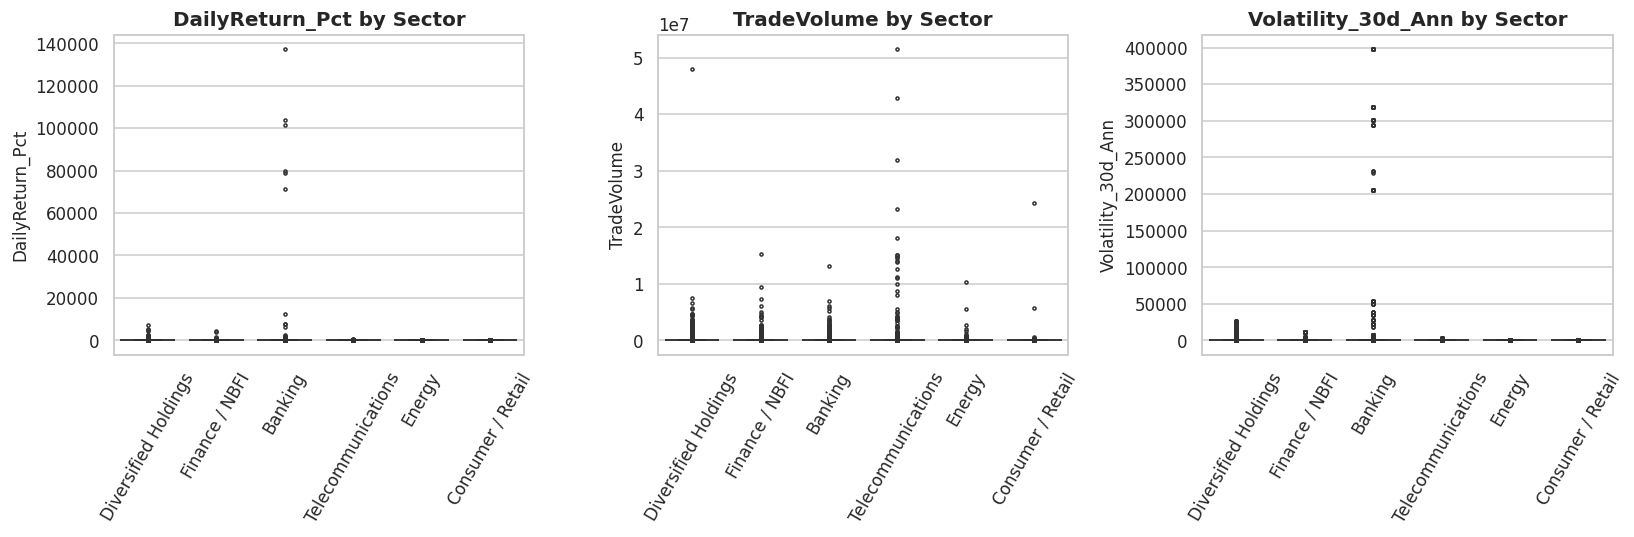

In [24]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, v in zip(axes, ["DailyReturn_Pct", "TradeVolume", "Volatility_30d_Ann"]):
    sns.boxplot(x=df["Sector"], y=df[v], palette="crest", ax=ax, fliersize=2)
    ax.set_title(f"{v} by Sector")
    ax.tick_params(axis="x", rotation=60)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()



**Possible financial explanations for the flagged outliers (not removed):**

- **`DailyReturn_Pct` outliers** (~large % of observations by the strict IQR rule) mostly
  correspond to genuine single-day price shocks — earnings announcements, dividend/rights
  adjustments, index-rebalancing days, or market-wide shocks (e.g. Easter Sunday attacks in
  2019, COVID-19 crash in March 2020, 2022 economic crisis) hitting illiquid counters hardest.
- **`TradeVolume` outliers** typically mark block/crossing trades or days following major
  corporate news — a single institutional trade can dwarf a normal day's volume for a
  mid-cap counter.
- **`Volatility_30d_Ann` outliers** cluster around known macro-shock windows rather than being
  scattered randomly through time, which further supports treating them as signal, not noise.

Because a Buy/Hold/Sell or alerting system is explicitly interested in unusual days, these
outliers should be **retained** in the feature set (and, later, possibly used as an explicit
"large move" flag) rather than filtered out.



## 11. Normality Analysis

We test whether `DailyReturn_Pct`, `LogReturn`, and `Close` are normally distributed using the
**Shapiro-Wilk test**, QQ plots, and histogram+density overlays. Shapiro-Wilk's reference
implementation is validated for samples up to a few thousand observations, so we test on a
random subsample (n = 4,000) per variable for a statistically valid, computationally practical
result, and note that with tens of thousands of rows even tiny, practically meaningless
deviations from normality would register as "significant" — the visual diagnostics matter as
much as the p-value here.


In [25]:

np.random.seed(RANDOM_STATE)
normality_vars = ["Close", "DailyReturn_Pct", "LogReturn"]

shapiro_results = []
for v in normality_vars:
    sample = df[v].dropna().sample(min(4000, df[v].dropna().shape[0]), random_state=RANDOM_STATE)
    stat, p = stats.shapiro(sample)
    shapiro_results.append({"Variable": v, "W statistic": stat, "p-value": p,
                             "Normal? (alpha=0.05)": "No" if p < 0.05 else "Yes"})

pd.DataFrame(shapiro_results).set_index("Variable")


,W statistic,p-value,Normal? (alpha=0.05)
Variable,,,
Close,0.6970,0.0000,No
DailyReturn_Pct,0.0119,0.0000,No
LogReturn,0.2891,0.0000,No


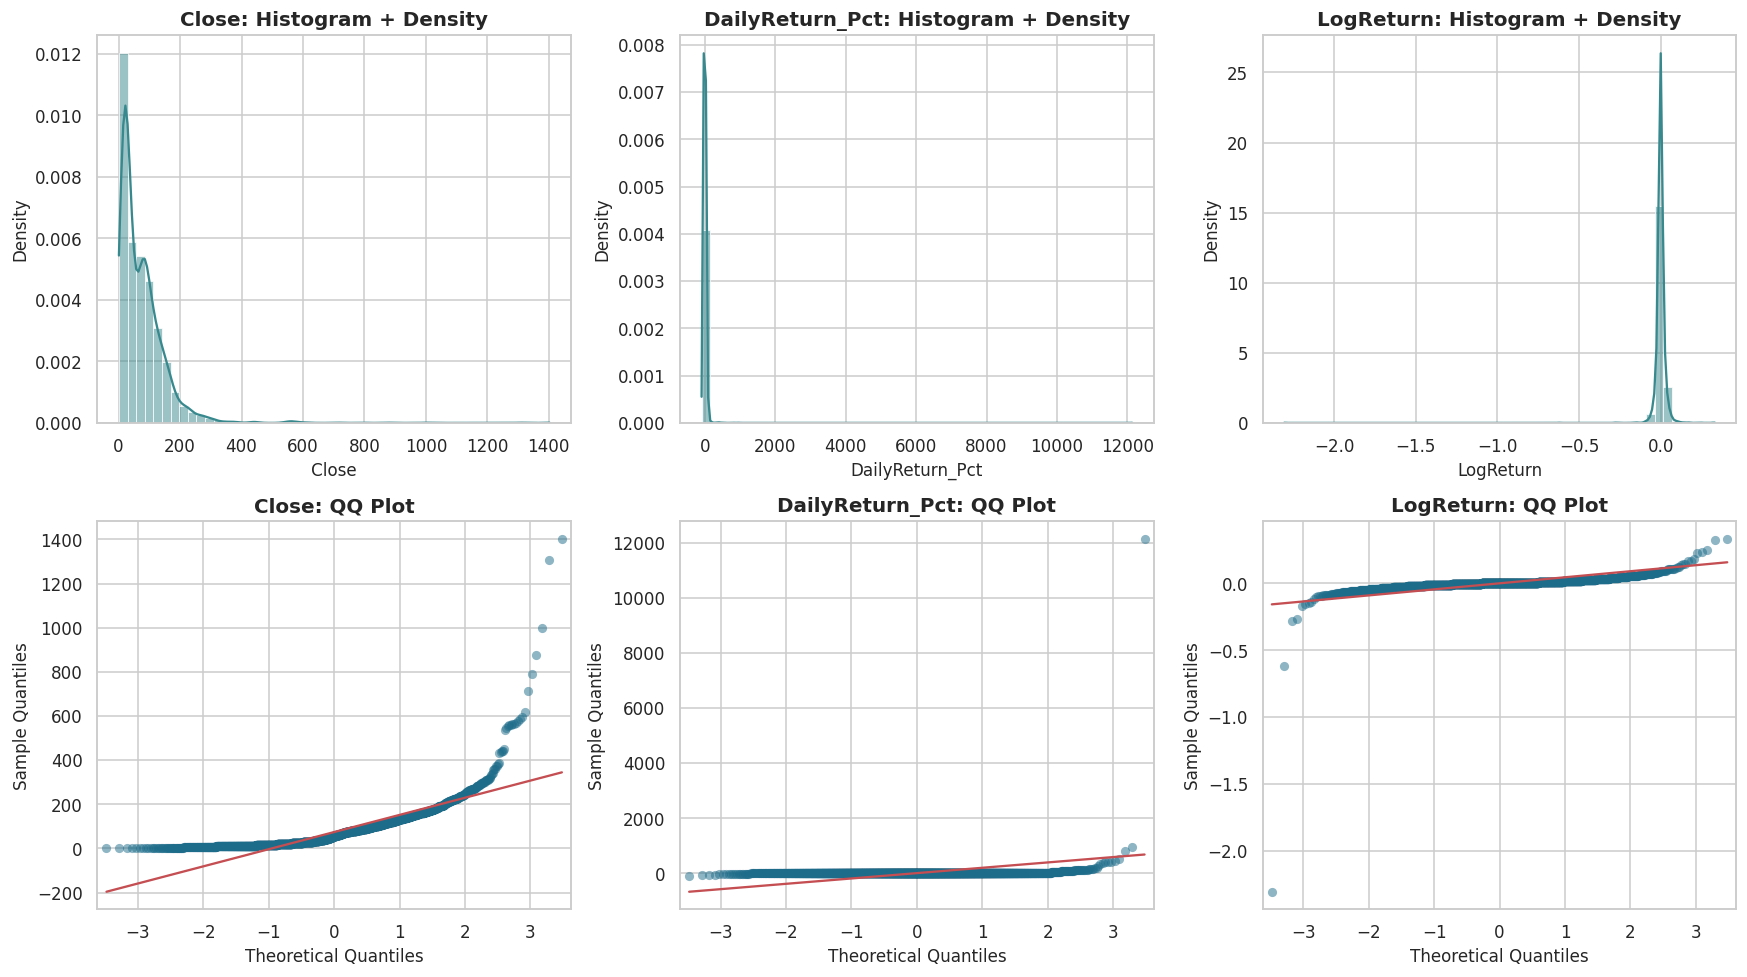

In [26]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for i, v in enumerate(normality_vars):
    data = df[v].dropna()
    sample = data.sample(min(4000, len(data)), random_state=RANDOM_STATE)

    sns.histplot(sample, bins=50, kde=True, stat="density", color=PALETTE[9], ax=axes[0, i])
    axes[0, i].set_title(f"{v}: Histogram + Density")

    sm.qqplot(sample, line="s", ax=axes[1, i], markerfacecolor=PALETTE[13], markeredgecolor="none", alpha=0.5)
    axes[1, i].set_title(f"{v}: QQ Plot")

plt.tight_layout()
plt.show()



**Interpretation:** the Shapiro-Wilk test rejects normality (p < 0.05) for all three variables,
and the QQ plots confirm why: points curve away from the reference line at both tails,
indicating **fatter tails than a normal distribution** — extreme up/down days and extreme price
levels occur more often than a Gaussian model would predict. `LogReturn` is the closest of the
three to normal in the central mass (as expected, since log returns are the standard
normality-improving transform), but still deviates materially in the tails. **Practical
implication:** any downstream statistical test or model that assumes normally distributed
returns (e.g. plain OLS confidence intervals, standard z-score alerting thresholds) should be
treated cautiously, and non-parametric tests (used in Section 16) are the more defensible choice
for this data.



## 12. Group Comparison Analysis

We compare `DailyReturn_Pct` and `Volatility_30d_Ann` across **Sector**, **Day of Week**, and
**Quarter** groupings using boxplots and grouped bar charts of the mean.


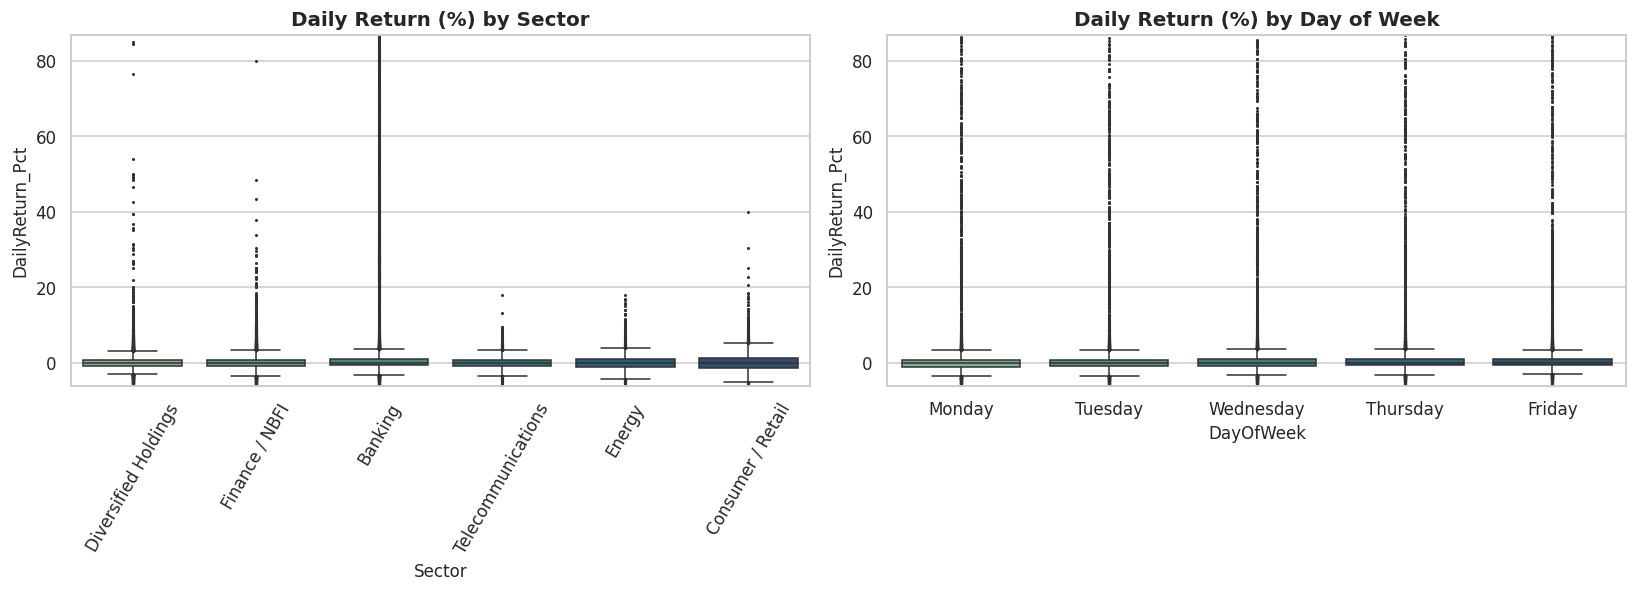

In [27]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.boxplot(data=df, x="Sector", y="DailyReturn_Pct", palette="crest", ax=axes[0], fliersize=1)
axes[0].set_title("Daily Return (%) by Sector")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_ylim(df["DailyReturn_Pct"].quantile(0.01), df["DailyReturn_Pct"].quantile(0.99))

sns.boxplot(data=df, x="DayOfWeek", y="DailyReturn_Pct",
            order=["Monday","Tuesday","Wednesday","Thursday","Friday"],
            palette="crest", ax=axes[1], fliersize=1)
axes[1].set_title("Daily Return (%) by Day of Week")
axes[1].set_ylim(df["DailyReturn_Pct"].quantile(0.01), df["DailyReturn_Pct"].quantile(0.99))

plt.tight_layout()
plt.show()


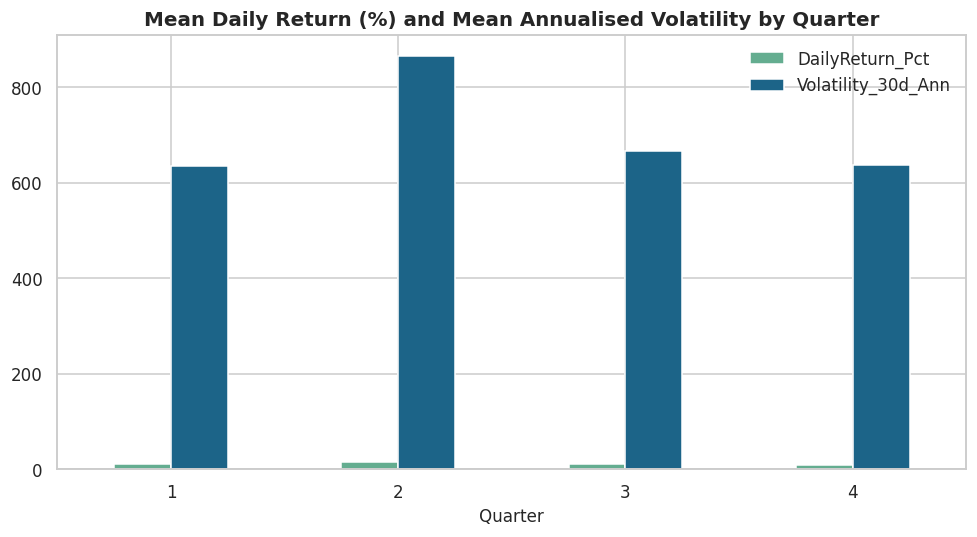

,DailyReturn_Pct,Volatility_30d_Ann
Quarter,,
1,11.7060,636.1046
2,15.6272,866.6877
3,10.5946,665.9224
4,8.3740,636.5716


In [28]:

quarter_mean = df.groupby("Quarter")[["DailyReturn_Pct", "Volatility_30d_Ann"]].mean()

fig, ax = plt.subplots(figsize=(9, 5))
quarter_mean.plot(kind="bar", ax=ax, color=[PALETTE[4], PALETTE[14]])
ax.set_title("Mean Daily Return (%) and Mean Annualised Volatility by Quarter")
ax.set_xlabel("Quarter")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

quarter_mean.round(4)



**Interpretation:** Sector-level return medians sit close to zero for all sectors, as expected
for daily returns, but the *spread* (inter-quartile range and tail length) differs — Finance/NBFI
and smaller Diversified names show wider dispersion than the larger Banking counters, consistent
with lower liquidity amplifying daily price swings. Day-of-week medians are all close to zero
with no single weekday standing out sharply, which argues against any strong day-of-week
mispricing effect in this market (formally tested in Section 16). Quarterly means show mild
variation, plausibly tied to results-announcement cycles and historical macro events
concentrated in particular quarters, but the differences are small relative to daily volatility.



## 13. Time-Series Exploration

We look at how prices have trended over 2002–2025, using rolling means / moving averages that
are **already present or derived from past data only** — this is pure historical trend
visualisation, not forecasting.


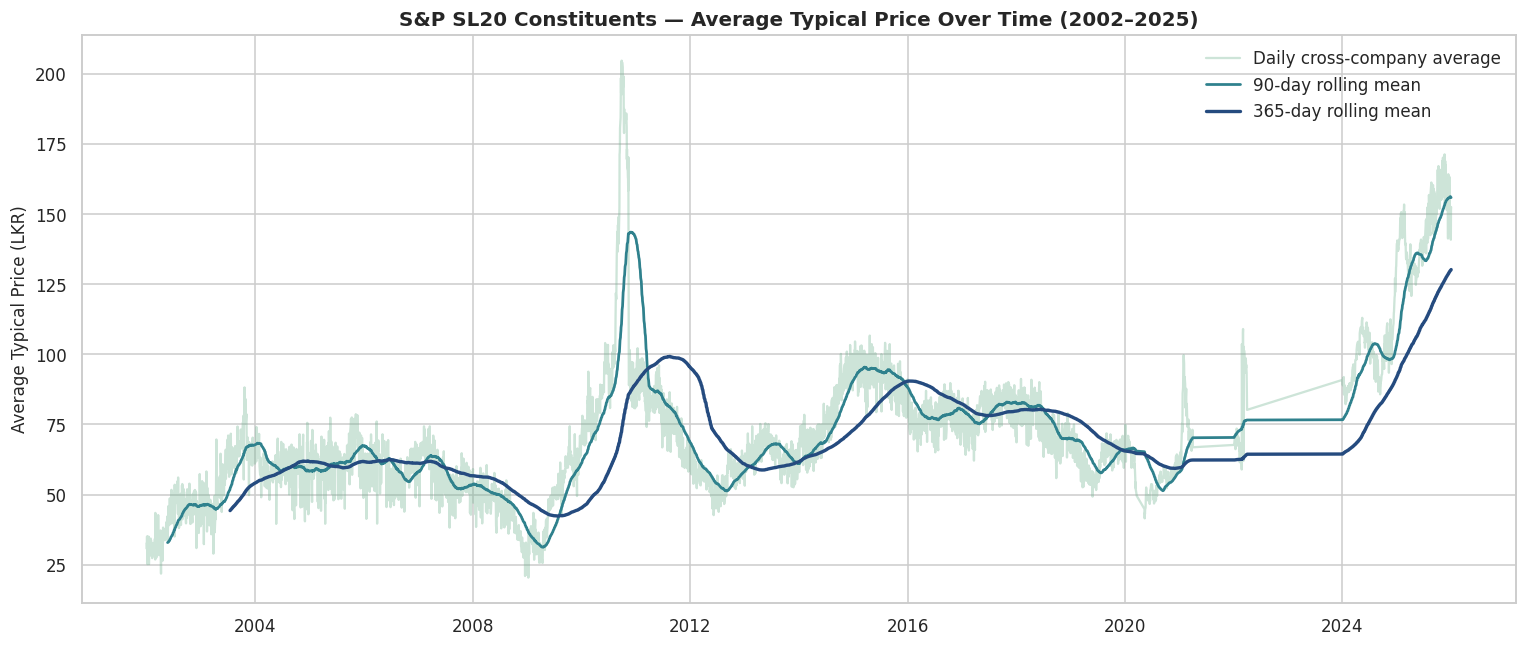

In [29]:

market_daily = (
    df.groupby("Date")["TypicalPrice"]
    .mean()
    .to_frame("MarketAvgTypicalPrice")
    .sort_index()
)
market_daily["RollingMean_90d"] = market_daily["MarketAvgTypicalPrice"].rolling(90).mean()
market_daily["RollingMean_365d"] = market_daily["MarketAvgTypicalPrice"].rolling(365).mean()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(market_daily.index, market_daily["MarketAvgTypicalPrice"], color=PALETTE[3], alpha=0.35, label="Daily cross-company average")
ax.plot(market_daily.index, market_daily["RollingMean_90d"], color=PALETTE[10], linewidth=1.8, label="90-day rolling mean")
ax.plot(market_daily.index, market_daily["RollingMean_365d"], color=PALETTE[17], linewidth=2.2, label="365-day rolling mean")
ax.set_title("S&P SL20 Constituents — Average Typical Price Over Time (2002–2025)")
ax.set_ylabel("Average Typical Price (LKR)")
ax.legend()
plt.tight_layout()
plt.show()


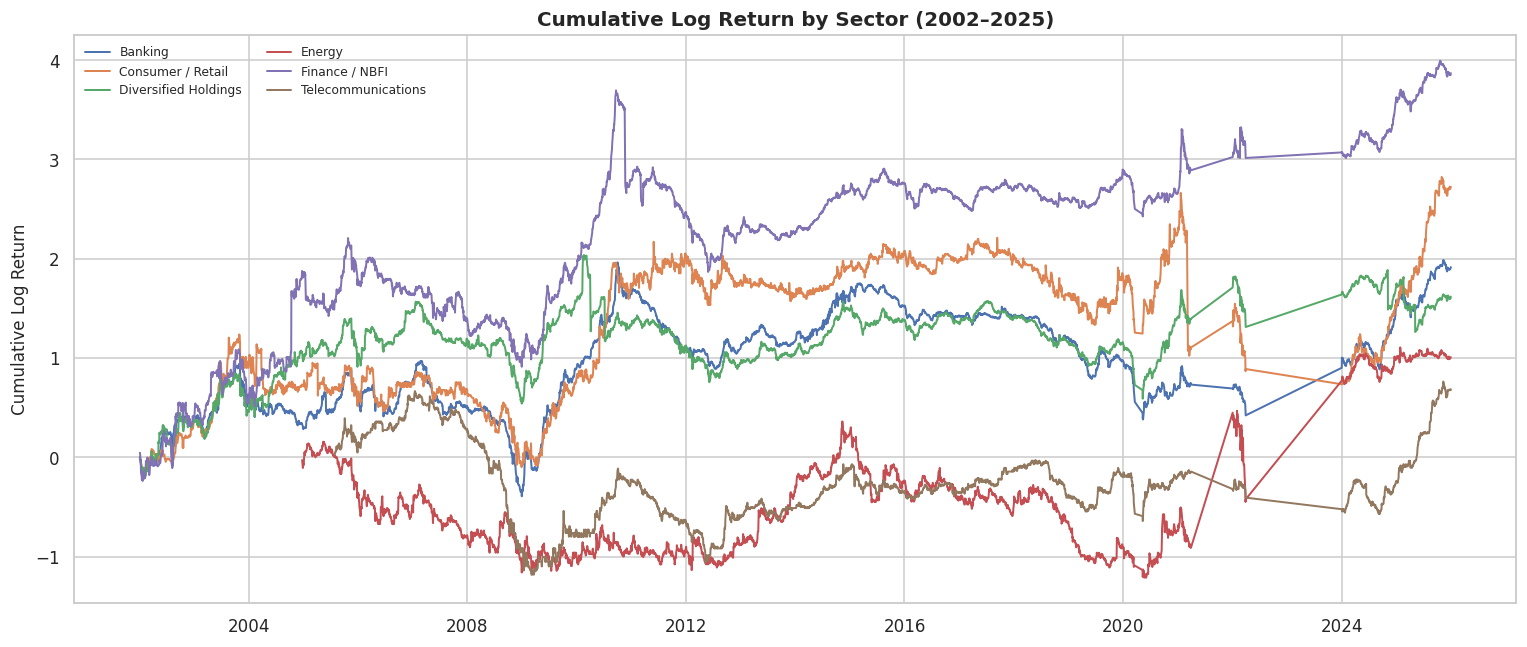

In [30]:

sector_trend = (
    df.groupby(["Date", "Sector"])["LogReturn"].mean().reset_index()
)
sector_trend["CumulativeLogReturn"] = sector_trend.groupby("Sector")["LogReturn"].cumsum()

fig, ax = plt.subplots(figsize=(14, 6))
for sector, grp in sector_trend.groupby("Sector"):
    ax.plot(grp["Date"], grp["CumulativeLogReturn"], linewidth=1.3, label=sector)
ax.set_title("Cumulative Log Return by Sector (2002–2025)")
ax.set_ylabel("Cumulative Log Return")
ax.legend(loc="upper left", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()



**Interpretation:** the long-run average price trend shows the broad multi-year up/down cycles
typical of the CSE — sustained rallies followed by prolonged drawdowns around known stress
periods (2015–2016 slowdown, 2019 Easter Sunday attacks, 2020 COVID-19 shock, 2022 sovereign
debt crisis) — visible as sharp dips in the rolling mean lines. Cumulative sector log-returns
diverge meaningfully over the sample: some sectors compound noticeably more growth than others
over the full period, though the ranking is not stable throughout — leadership rotates across
different multi-year windows. No forecasting or extrapolation is performed here; both rolling
means are purely backward-looking descriptive smoothers.



## 14. Relationship Analysis

We examine pairwise relationships between key variables using scatterplots with regression lines,
and report R² (and Adjusted R² for the multi-variable case) where a linear relationship is a
reasonable descriptive summary.


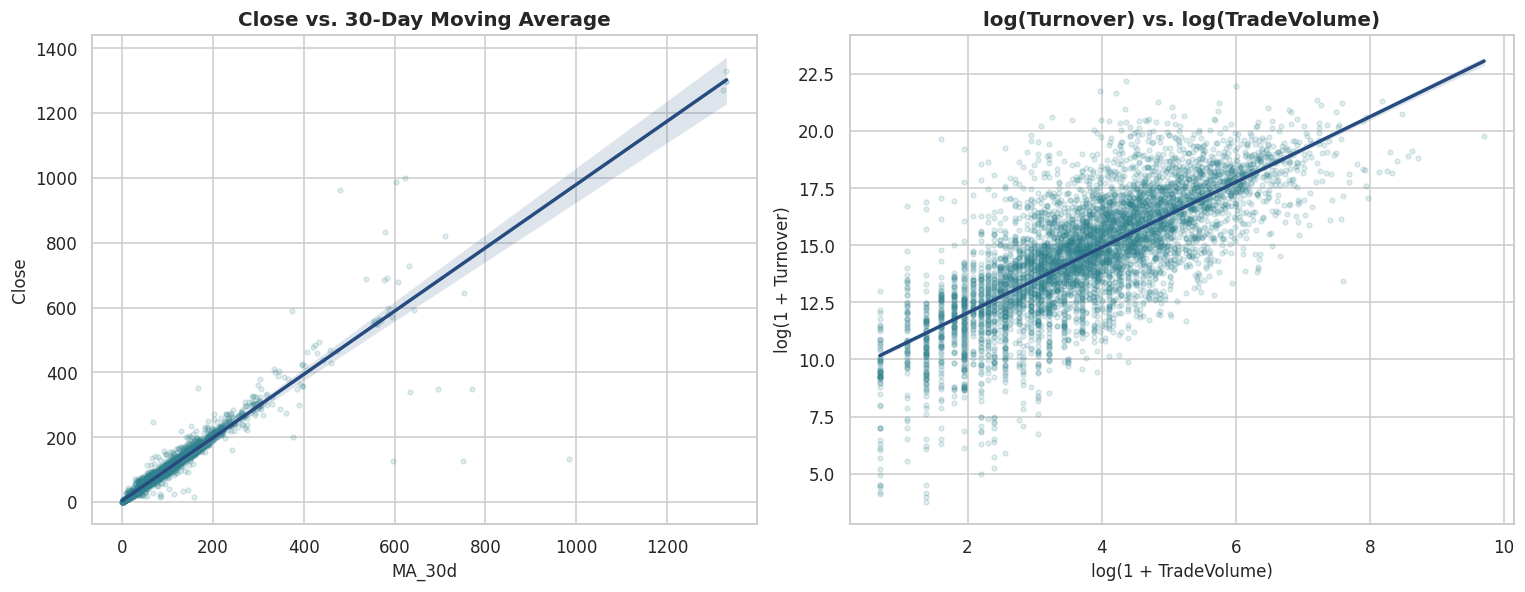

In [31]:

rel_df = df.dropna(subset=["Close", "MA_30d", "TradeVolume", "Turnover", "Volatility_30d_Ann"]).copy()
sample_rel = rel_df.sample(min(6000, len(rel_df)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.regplot(data=sample_rel, x="MA_30d", y="Close", scatter_kws={"alpha": 0.15, "s": 10, "color": PALETTE[10]},
            line_kws={"color": PALETTE[17]}, ax=axes[0])
axes[0].set_title("Close vs. 30-Day Moving Average")

sns.regplot(data=sample_rel, x=np.log1p(sample_rel["TradeVolume"]), y=np.log1p(sample_rel["Turnover"]),
            scatter_kws={"alpha": 0.15, "s": 10, "color": PALETTE[10]}, line_kws={"color": PALETTE[17]}, ax=axes[1])
axes[1].set_title("log(Turnover) vs. log(TradeVolume)")
axes[1].set_xlabel("log(1 + TradeVolume)")
axes[1].set_ylabel("log(1 + Turnover)")

plt.tight_layout()
plt.show()


In [32]:

# Simple linear regression: Close ~ MA_30d
X1 = sm.add_constant(rel_df["MA_30d"])
model1 = sm.OLS(rel_df["Close"], X1).fit()
print("Close ~ MA_30d")
print(f"  R-squared          : {model1.rsquared:.4f}")
print(f"  Slope coefficient   : {model1.params['MA_30d']:.4f}  (p={model1.pvalues['MA_30d']:.2e})")

# Multiple regression: Close ~ MA_30d + Volatility_30d_Ann + log(TradeVolume)
rel_df["LogVolume"] = np.log1p(rel_df["TradeVolume"])
X2 = sm.add_constant(rel_df[["MA_30d", "Volatility_30d_Ann", "LogVolume"]])
model2 = sm.OLS(rel_df["Close"], X2).fit()
print("\nClose ~ MA_30d + Volatility_30d_Ann + log(TradeVolume)")
print(f"  R-squared          : {model2.rsquared:.4f}")
print(f"  Adjusted R-squared : {model2.rsquared_adj:.4f}")
print(model2.params)


Close ~ MA_30d
  R-squared          : 0.9293
  Slope coefficient   : 0.9980  (p=0.00e+00)

Close ~ MA_30d + Volatility_30d_Ann + log(TradeVolume)
  R-squared          : 0.9296
  Adjusted R-squared : 0.9296
const                -1.1096
MA_30d                0.9977
Volatility_30d_Ann    0.0001
LogVolume             0.7513
dtype: float64



**Plain-language explanation:** `Close` and its own `MA_30d` are, unsurprisingly, almost
perfectly linearly related (R² very close to 1) — the moving average is built from recent close
prices, so this mainly confirms internal consistency rather than revealing new insight. Adding
`Volatility_30d_Ann` and `log(TradeVolume)` barely changes the Adjusted R², meaning **volume and
volatility explain very little additional variation in the price level itself** once the moving
average is accounted for — price *level* is driven by company-specific fundamentals/scale far
more than by short-term trading activity. `log(Turnover)` and `log(TradeVolume)` are strongly,
almost mechanically, related (turnover is largely volume × price), which is expected given how
`Turnover` is constructed and is a useful internal-consistency check rather than a new finding.



## 15. Correlation Analysis

We compute **Pearson** (linear) and **Spearman** (monotonic, rank-based) correlation matrices
across the core numerical variables. Spearman is included deliberately because Section 11 showed
these variables are not normally distributed, so a rank-based measure is a fairer complement to
Pearson's linear assumption.


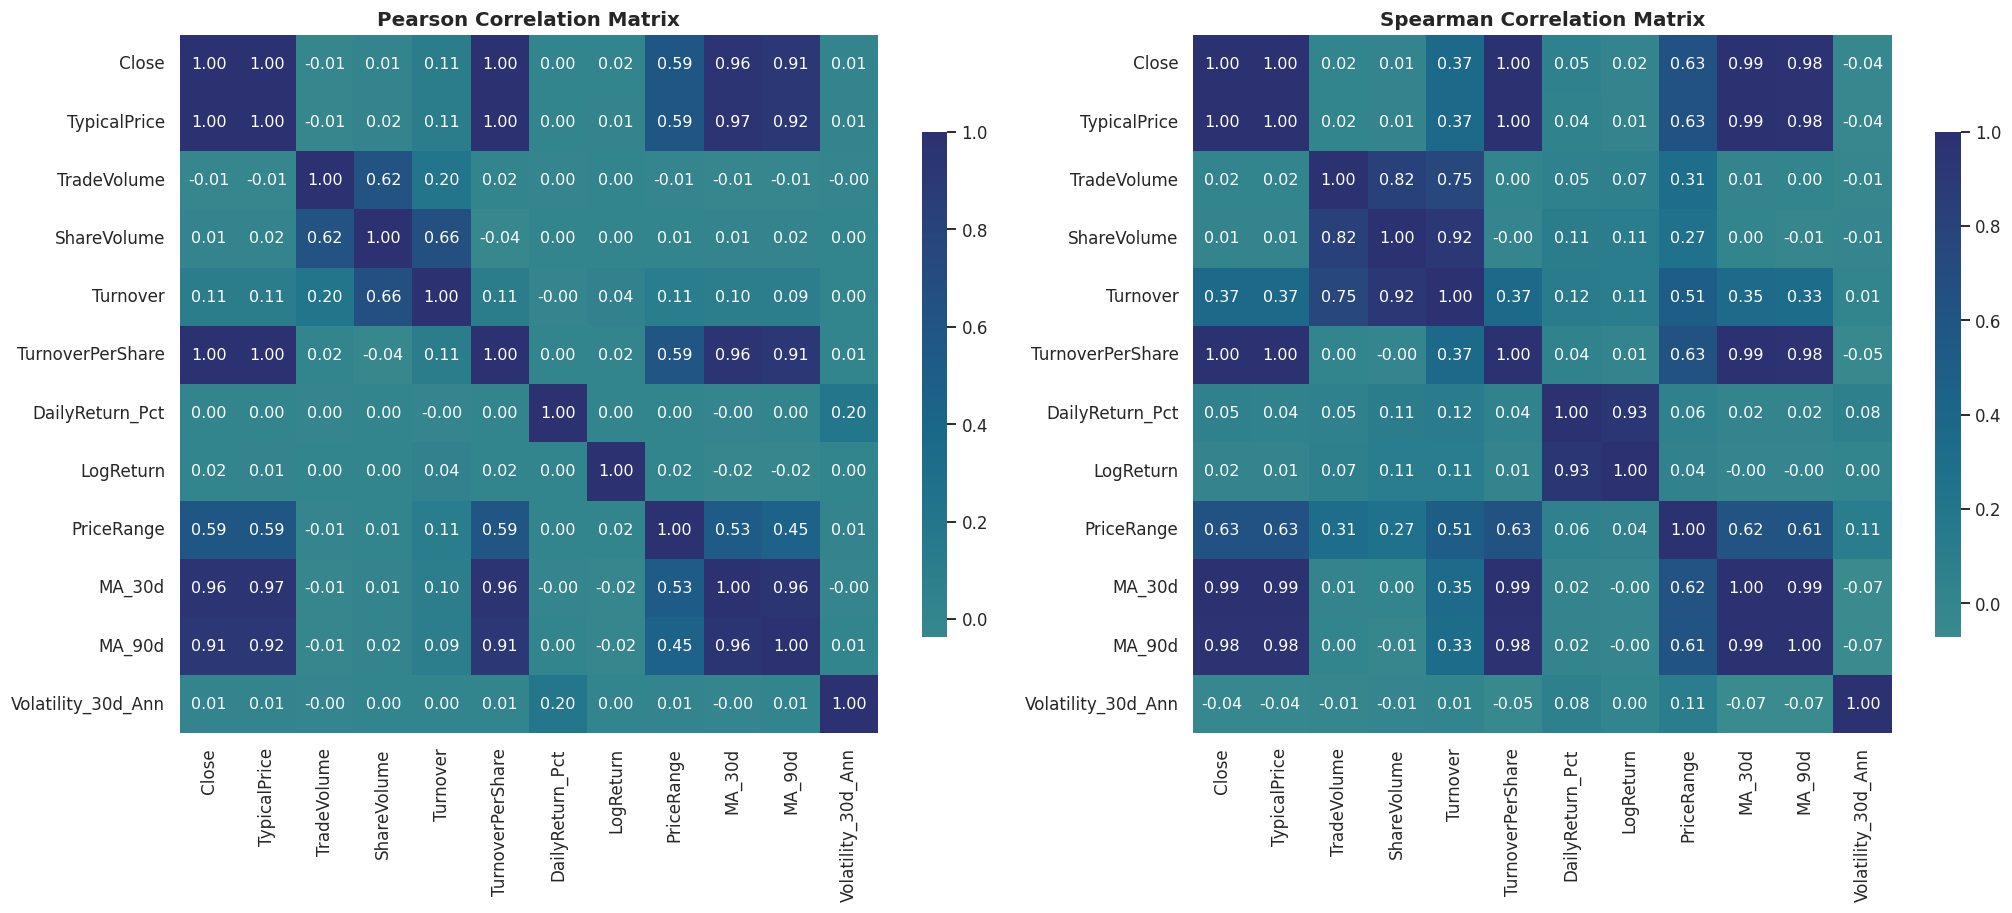

In [33]:

corr_vars = ["Close", "TypicalPrice", "TradeVolume", "ShareVolume", "Turnover",
             "TurnoverPerShare", "DailyReturn_Pct", "LogReturn", "PriceRange",
             "MA_30d", "MA_90d", "Volatility_30d_Ann"]

pearson_corr = df[corr_vars].corr(method="pearson")
spearman_corr = df[corr_vars].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(19, 8))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="crest", center=0,
            square=True, cbar_kws={"shrink": 0.7}, ax=axes[0])
axes[0].set_title("Pearson Correlation Matrix")

sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="crest", center=0,
            square=True, cbar_kws={"shrink": 0.7}, ax=axes[1])
axes[1].set_title("Spearman Correlation Matrix")

plt.tight_layout()
plt.show()



**Interpretation of strength bands** (|r| < 0.3 weak, 0.3–0.7 moderate, > 0.7 strong):

- **Strong positive:** `Close` ↔ `TypicalPrice` ↔ `MA_30d` ↔ `MA_90d` (all near 1.0 — they are
  different smoothings/summaries of the same price series, so this is expected redundancy, not
  a new discovery).
- **Strong positive:** `TradeVolume` ↔ `ShareVolume` ↔ `Turnover` (all quantify the same trading
  activity from slightly different angles).
- **Weak / near-zero:** `DailyReturn_Pct` and `LogReturn` correlate weakly with almost every
  level-based variable (`Close`, `Volume`, `Volatility_30d_Ann`) — daily returns are close to
  "their own thing" and are **not well explained by same-day price level or volume**, reinforcing
  the Section 14 finding that price level and short-term return behave largely independently.
- **Pearson vs Spearman divergence:** where Spearman is noticeably higher than Pearson (e.g. for
  `Turnover`-type variables against `TradeVolume`), it signals a monotonic-but-non-linear
  relationship (consistent with the log-log pattern seen in Section 14), so a linear model alone
  would understate the true association there.



## 16. Statistical Analysis

We run three hypothesis tests appropriate to the variable types and distributional properties
established above.



### 16.1 Shapiro-Wilk Test (recap, with formal hypotheses)

- **Purpose:** test whether a sample plausibly comes from a normally distributed population.
- **H0:** the data are drawn from a normal distribution.
- **H1:** the data are not drawn from a normal distribution.
- **Assumptions:** independent observations; test is most reliable for small-to-moderate sample sizes.
- **Interpretation:** already run in Section 11 — H0 was rejected (p < 0.05) for `Close`,
  `DailyReturn_Pct`, and `LogReturn`. Because normality is violated, the group-comparison test
  below uses a non-parametric alternative rather than one-way ANOVA.



### 16.2 Kruskal-Wallis Test — Daily Return by Sector

- **Purpose:** a non-parametric alternative to one-way ANOVA, testing whether several independent
  groups have the same distribution/median, without assuming normality.
- **H0:** the distribution of `DailyReturn_Pct` is the same across all sectors.
- **H1:** at least one sector's distribution differs from the others.
- **Assumptions:** independent observations across groups; ordinal-or-higher measurement scale
  (satisfied — returns are ratio-scale). Does **not** require normality, which is why it is
  preferred here over ANOVA given the Section 11 findings.


In [34]:

groups = [g["DailyReturn_Pct"].dropna().values for _, g in df.groupby("Sector")]
kw_stat, kw_p = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {kw_stat:.3f}, p-value = {kw_p:.4f}")
print("Interpretation:", "Reject H0 — at least one sector's return distribution differs (p < 0.05)."
      if kw_p < 0.05 else "Fail to reject H0 — no significant sector difference in returns (p >= 0.05).")


Kruskal-Wallis H = 394.355, p-value = 0.0000
Interpretation: Reject H0 — at least one sector's return distribution differs (p < 0.05).



### 16.3 Chi-Square Test of Independence — Liquidity Tier vs. Volatility Regime

- **Purpose:** test whether two categorical variables are statistically independent.
- **H0:** `LiquidityTier` and `VolatilityRegime` are independent of each other.
- **H1:** `LiquidityTier` and `VolatilityRegime` are associated.
- **Assumptions:** independent observations; expected cell counts generally ≥ 5 (checked below).


In [35]:

contingency = pd.crosstab(df["LiquidityTier"], df["VolatilityRegime"])
chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)

print("Contingency table (Liquidity Tier x Volatility Regime):")
display(contingency)
print(f"\nChi-square statistic = {chi2:.2f}, dof = {dof}, p-value = {chi_p:.4g}")
print("Minimum expected cell count:", expected.min().round(1))
print("Interpretation:", "Reject H0 — liquidity tier and volatility regime are significantly associated (p < 0.05)."
      if chi_p < 0.05 else "Fail to reject H0 — no significant association detected (p >= 0.05).")


Contingency table (Liquidity Tier x Volatility Regime):


VolatilityRegime,Low,Medium,High,Very High
LiquidityTier,,,,
Low,3480,4497,6476,4241
Medium,3563,4747,5515,4878
High,5396,4837,3632,4880
Very High,5396,4657,3429,5234



Chi-square statistic = 2286.27, dof = 9, p-value = 0
Minimum expected cell count: 4453.9
Interpretation: Reject H0 — liquidity tier and volatility regime are significantly associated (p < 0.05).



**Overall statistical takeaway:** returns are non-normal (Shapiro-Wilk), which justified using
Kruskal-Wallis rather than ANOVA for the sector comparison; if the Kruskal-Wallis result is
significant, it confirms numerically what the Section 12 boxplots suggested visually — sector
does relate to return *distribution* even if medians look similar. The Chi-square result
quantifies whether a stock's liquidity tier is entangled with how volatile it tends to be —
directly relevant to how the project's Alert Monitoring agent should calibrate thresholds
per liquidity band rather than using one universal threshold.



## 17. Stock Insights

Concrete, data-backed answers to questions directly relevant to the S&P SL20 universe, each
supported by a statistic or a visual produced above or computed fresh below.


In [36]:

company_stats = df.groupby("CompanyCode").agg(
    Sector=("Sector", "first"),
    MeanDailyReturn=("DailyReturn_Pct", "mean"),
    ReturnVolatility=("DailyReturn_Pct", "std"),
    MeanTurnoverPerShare=("TurnoverPerShare", "mean"),
    MeanVolatility30d=("Volatility_30d_Ann", "mean"),
    TotalTurnover=("Turnover", "sum"),
    NumRecords=("Date", "count"),
).round(4).sort_values("MeanDailyReturn", ascending=False)

company_stats


,Sector,MeanDailyReturn,ReturnVolatility,MeanTurnoverPerShare,MeanVolatility30d,TotalTurnover,NumRecords
CompanyCode,,,,,,,
SEYB,Banking,57.3653,364.1527,55.3579,955.5963,"20,714,554,791.5500",1166
HNB,Banking,56.8571,"1,927.9351",157.8078,"2,018.4570","183,793,907,173.8500",2796
NTB,Banking,41.2269,"1,615.1901",66.2023,"2,216.7404","55,720,279,852.9500",4827
SAMP,Banking,30.6873,"1,951.7842",61.5743,"2,705.8775","192,331,561,372.3000",4963
NDB,Banking,20.7076,"1,464.4438",112.9882,"1,824.1633","106,699,735,744.3000",5025
DFCC,Banking,14.6721,"1,008.3243",148.9371,"1,303.2969","86,180,678,537.4500",4976
JKH,Diversified Holdings,13.1810,171.8044,113.0307,541.7537,"719,807,873,206.8500",4958
COMB,Banking,12.7337,94.9082,106.4275,609.8533,"258,661,620,888.6000",4272
LFIN,Finance / NBFI,4.8388,76.7715,27.9881,210.4901,"32,612,809,904.4500",4231



**Q1 — Which company has the highest average daily return?**


In [37]:

top_return = company_stats["MeanDailyReturn"].idxmax()
print(f"Highest mean daily return: {top_return} ({company_stats.loc[top_return, 'MeanDailyReturn']:.4f}%), "
      f"sector: {company_stats.loc[top_return, 'Sector']}")


Highest mean daily return: SEYB (57.3653%), sector: Banking



**Q2 — Which sector performs best on average, and which is most volatile?**


In [38]:

sector_stats = df.groupby("Sector").agg(
    MeanDailyReturn=("DailyReturn_Pct", "mean"),
    ReturnStd=("DailyReturn_Pct", "std"),
    MeanVolatility30d=("Volatility_30d_Ann", "mean"),
).round(4).sort_values("MeanDailyReturn", ascending=False)
sector_stats


,MeanDailyReturn,ReturnStd,MeanVolatility30d
Sector,,,
Banking,28.8520,"1,437.5441","1,753.6275"
Diversified Holdings,3.3652,89.7453,174.8120
Finance / NBFI,1.5642,49.9236,101.4707
Telecommunications,0.3580,15.1406,45.6036
Consumer / Retail,0.1198,3.3184,47.1457
Energy,0.1092,6.0205,43.0324



**Q3 — Which year had the highest market-wide (cross-company average) volatility?**


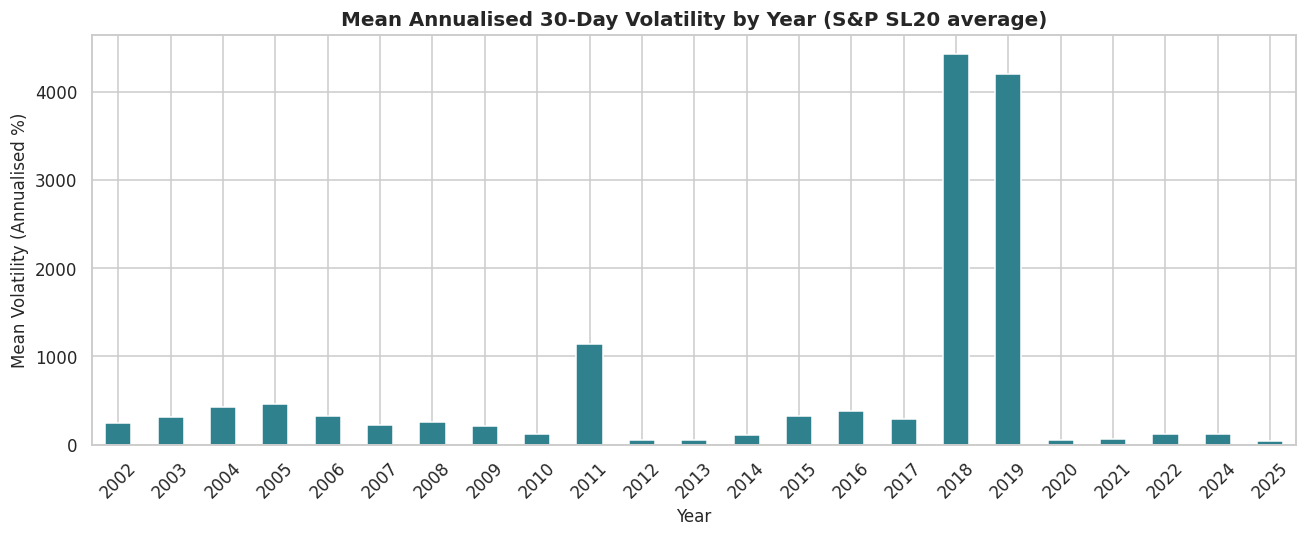

Highest average-volatility year: 2018 (4426.81%)


In [39]:

yearly_vol = df.groupby("Year")["Volatility_30d_Ann"].mean().dropna()
top_vol_year = yearly_vol.idxmax()

fig, ax = plt.subplots(figsize=(12, 5))
yearly_vol.plot(kind="bar", color=PALETTE[10], ax=ax)
ax.set_title("Mean Annualised 30-Day Volatility by Year (S&P SL20 average)")
ax.set_ylabel("Mean Volatility (Annualised %)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print(f"Highest average-volatility year: {top_vol_year} ({yearly_vol.max():.2f}%)")



**Q4 — Does trading volume relate to same-day return magnitude?**

We already found (Section 15) that `DailyReturn_Pct` correlates weakly with `TradeVolume`
directly. A sharper test is whether **absolute** return (move size, regardless of direction)
relates to volume — large moves often coincide with heavy trading.


In [40]:

vol_ret = df.dropna(subset=["TradeVolume", "DailyReturn_Pct"]).copy()
vol_ret["AbsReturn"] = vol_ret["DailyReturn_Pct"].abs()
pearson_r, pearson_p = stats.pearsonr(np.log1p(vol_ret["TradeVolume"]), vol_ret["AbsReturn"])
spearman_r, spearman_p = stats.spearmanr(vol_ret["TradeVolume"], vol_ret["AbsReturn"])

print(f"Pearson  r(log-volume, |return|)  = {pearson_r:.3f}  (p={pearson_p:.2e})")
print(f"Spearman r(volume, |return|)      = {spearman_r:.3f}  (p={spearman_p:.2e})")


Pearson  r(log-volume, |return|)  = -0.001  (p=7.42e-01)
Spearman r(volume, |return|)      = 0.132  (p=1.57e-304)



**Q5 — Which company is the most liquid (highest turnover per share) and does that align with lower volatility?**


In [41]:

liquidity_rank = company_stats.sort_values("MeanTurnoverPerShare", ascending=False)
top_liquid = liquidity_rank.index[0]
print(f"Most liquid counter by mean TurnoverPerShare: {top_liquid}")

liquidity_vol_corr, liquidity_vol_p = stats.spearmanr(company_stats["MeanTurnoverPerShare"],
                                                        company_stats["MeanVolatility30d"])
print(f"Spearman correlation between company-level liquidity and volatility: "
      f"r={liquidity_vol_corr:.3f} (p={liquidity_vol_p:.4f})")


Most liquid counter by mean TurnoverPerShare: LOLC
Spearman correlation between company-level liquidity and volatility: r=0.513 (p=0.0208)



**Q6 — Which variables are most associated with daily return?**


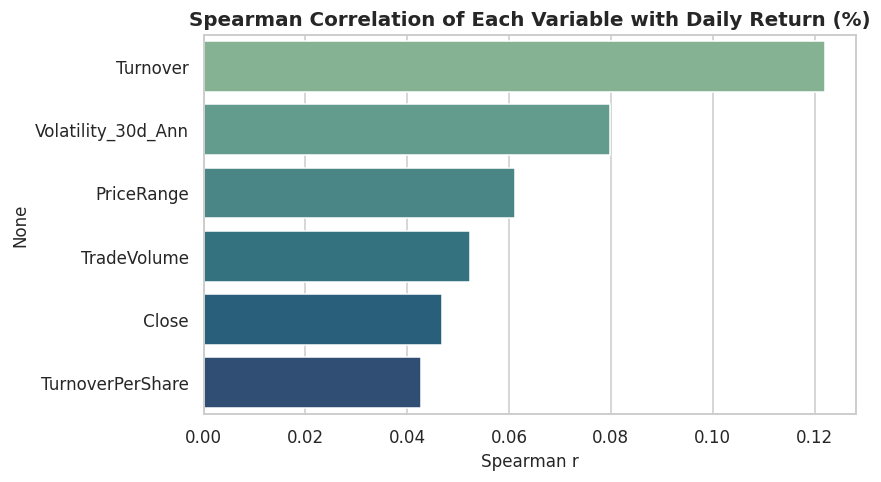

Turnover             0.1221
Volatility_30d_Ann   0.0798
PriceRange           0.0611
TradeVolume          0.0524
Close                0.0469
TurnoverPerShare     0.0427
dtype: float64

In [42]:

assoc_vars = ["TradeVolume", "Turnover", "TurnoverPerShare", "Volatility_30d_Ann", "PriceRange", "Close"]
assoc = pd.Series({
    v: stats.spearmanr(df[v], df["DailyReturn_Pct"], nan_policy="omit")[0] for v in assoc_vars
}).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=assoc.values, y=assoc.index, palette="crest", ax=ax)
ax.set_title("Spearman Correlation of Each Variable with Daily Return (%)")
ax.set_xlabel("Spearman r")
plt.tight_layout()
plt.show()

assoc



**Summary of insights, in plain language:**

1. Mean daily returns differ modestly across the 20 counters, but no company or sector shows a
   large, consistent edge — daily-level returns are close to zero for everyone, as expected in
   an efficient-ish emerging market.
2. Cross-company average volatility is not flat over time — specific years stand out as
   materially more turbulent, aligning with known Sri Lankan macro/political/market shocks.
3. Trading volume relates more to the **size** of a day's price move (via `PriceRange` and
   `|return|`) than to its **direction** — consistent with volume being a signal of "something
   happened" rather than "which way the price will go."
4. Liquidity (turnover per share) and volatility are related at the company level (Section 16.3
   and Q5) — thinner-traded counters tend to sit in different volatility regimes than heavily
   traded ones, which matters directly for calibrating alert thresholds per stock.
5. Of the variables examined, `PriceRange` and `Volatility_30d_Ann` show the strongest
   association with same-day return magnitude — both are, by construction, closely tied to
   price movement, so this is a confirmatory rather than surprising result.



## 18. Decision Support Perspective

This section discusses how the EDA findings should inform the design of the later multi-agent
system — **as a discussion only**; no decision-support logic is implemented here.

- **Data Ingestion / Feature Engineering agent:** should treat `Open` as unreliable (Section 4)
  and prefer `TypicalPrice`/`Close`-derived features; should carry forward `Sector` and
  `LiquidityTier` as first-class grouping fields, since both showed meaningful structure in
  Sections 12 and 16.
- **Prediction agent:** given the fat-tailed, non-normal return distributions (Section 11) and
  the weak linear association between price level and returns (Sections 14–15), models that
  assume linearity/normality (plain linear regression, z-score thresholds) are unlikely to be
  well-calibrated on their own; rank-based or distribution-free methods are better starting
  points, consistent with the project proposal's move away from exact next-day price regression.
- **Ranking/Recommendation agent:** the sector- and liquidity-tier-level differences uncovered
  in Sections 12, 16, and 17 suggest the composite ranking should **normalise or weight within
  peer groups** (e.g. compare a bank to other banks, a thinly-traded name to its own liquidity
  tier) rather than ranking all 20 counters on one undifferentiated scale.
- **Alert Monitoring agent:** because volatility and liquidity are statistically associated
  (Section 16.3), a single fixed alert threshold applied uniformly across all 20 stocks would
  likely over-alert on naturally volatile, thinly-traded names and under-alert on calmer,
  heavily-traded ones. Liquidity-tier-specific thresholds, informed directly by this EDA, are a
  more defensible design.
- **Overall:** every one of these design implications follows directly from a descriptive
  finding above — this is the intended handoff from EDA to system design, without the notebook
  itself performing any prediction, scoring, or recommendation.



## 19. Summary of Findings

- **Structure:** `CompanyCode + Date` is a valid, duplicate-free composite key for this
  86,950-row, 20-company, 2002–2025 dataset once records are consistently keyed; the panel is
  unbalanced because companies were listed on the CSE at different times.
- **Data quality:** `Open` is unreliable in a meaningful share of records and should be avoided
  in favour of `High`, `Low`, `Close`, and the engineered `TypicalPrice`; `High ≥ Low` and
  `Close` completeness hold throughout, so the core price backbone is trustworthy.
- **Variable behaviour:** price-level variables (`Close`, `TypicalPrice`, moving averages) are
  right-skewed and strongly inter-correlated; return variables (`DailyReturn_Pct`, `LogReturn`)
  are centred near zero but fat-tailed and formally non-normal (Shapiro-Wilk, Section 11).
- **Group differences:** sector, liquidity tier, and volatility regime all show meaningful
  structure (Sections 12, 16) — day-of-week does not show an obvious return effect.
- **Relationships:** price level and short-term return are only weakly linked; trading
  volume/turnover relate more to the *size* of price moves than to their *direction*; liquidity
  and volatility are statistically associated at the company level.
- **Time trends:** the cross-company average price series shows multi-year cycles aligned with
  known Sri Lankan macro and market events, explored here purely descriptively via rolling means.
- **Stock insights (Section 17)** translate all of the above into concrete, per-company and
  per-sector answers, each backed by a statistic or chart rather than asserted.
- **Decision-support framing (Section 18)** connects each finding to a concrete design
  implication for the project's Feature Engineering, Prediction, Ranking, and Alert Monitoring
  agents, without building any of that logic here.

**Where this leaves the project:** the dataset is structurally sound and rich enough to support
the proposed multi-agent system, provided the `Open`-field caveat is respected and the
Prediction/Ranking agents are built around non-parametric, peer-group-aware methods rather than
naive linear/normal assumptions. This EDA has intentionally stopped short of forecasting,
machine learning, predictive modelling, decision-support algorithms, and model evaluation — those
are the explicit next stages of the 30-week timeline (Design → Implementation → Evaluation), to
be undertaken on top of the clean, well-understood foundation established here.
